# 時空図 ((r, t) 図と時間進化)

このノートブックのモデルと範囲は `thesis_common.ipynb` で指定する。変更したら先頭のセルから実行し直す。

コメント中の `cell N` は分割前の `thesis.ipynb` の番号で、各セルの1行目の `[旧 cell N]` と対応する。

# file_gas
# r_cen_[i] :0 sigmag_[i] :1 sigmad_tot_[i] :2 sigmad_vapor : 3 vg_r_[i] : 4 vg_phi_[i] :5 vg_wind_[i] :6 vd_r_tot[i][0] : 7 
# lambda1_[i]: 8 lambda2_[i] :9 dsigmagdt_w[i]:10 T_[i]:11 P_[i][nz_s] : 12 P_[i][nz_s]/beta_disk_[i][nz_s] : 13 Q_toomre[i] : 14 alpha_GI[i] : 15  
# alpha_phiz[i] : 16 alpha_tot[i] : 17 eta_P_[i] :18
# file_mag
# r_cen_[i] :0 alpha_MRI[i]:1 B_[i]:2 etaO_R[i]:3 etaA_R[i]:4 beta_disk_[i][nz_s]:5

In [10]:
# 共通設定を読み込む (モデルや範囲は thesis_common.ipynb で変更する)
import json

def run_nb(path):
    # 別のノートブックのコードセルをこのノートブックの変数空間で実行する
    for c in json.load(open(path))["cells"]:
        if c["cell_type"] == "code":
            exec("".join(c["source"]), globals())

run_nb("thesis_common.ipynb")

## 基本量

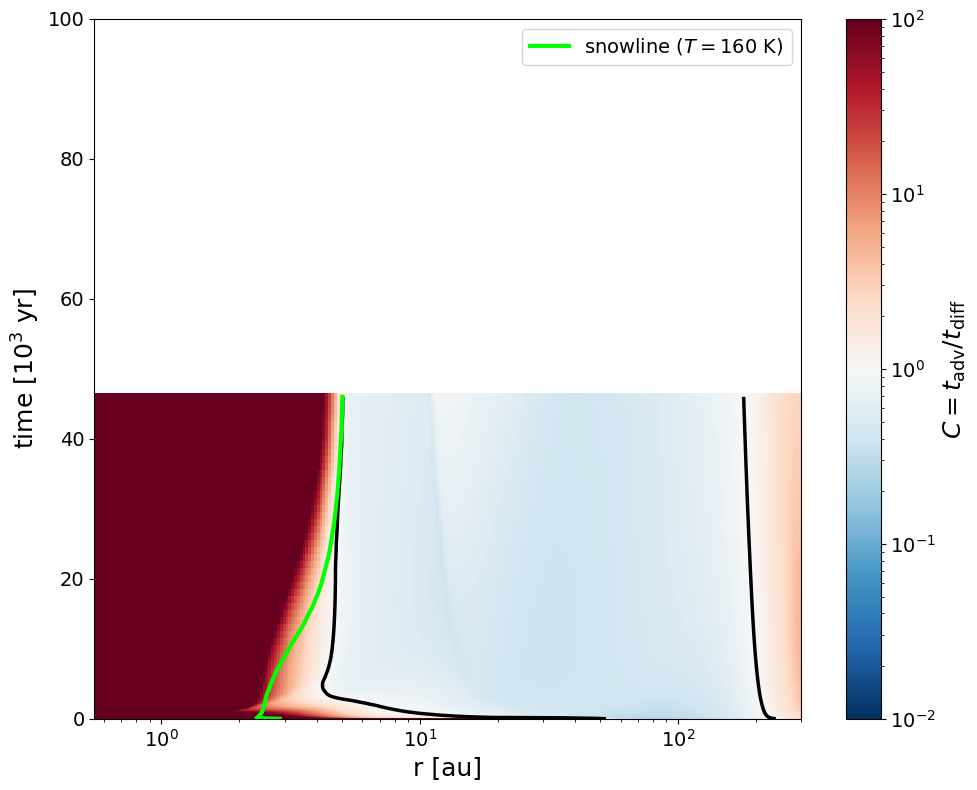

In [11]:
# [旧 cell 38]
# ======================================================
# 磁場の移流/拡散タイムスケール比 C = t_adv/t_diff の (r,t) 時空図 + スノーライン(T=160K)
# t_adv = r/|v_gr| , t_diff = r^2/eta_tot  ->  C = eta_tot/(r|v_gr|)
# eta_tot = min(etaO_R + etaA_R, eta_max)   (use_eta_floor = false のときのコードと同じ)
# file_gas 列: 0:r_cen 4:vg_r 12:T     file_mag 列: 0:r_cen 3:etaO_R 4:etaA_R
# ======================================================

AU = 1.495979e+13

outdir = BASE_DIR
resultdir = MODEL
eta_max = 1.0e20
t_start = 0

path_gas = outdir + resultdir
path_mag = outdir + resultdir + "_B"
years = list_years(path_gas, t_start, path_mag=path_mag)

logC, r_snow = [], []
for year in years:
    gas = np.loadtxt(path_gas + "/out{}_gas".format(year), usecols=(0, 4, 12))
    mag = np.loadtxt(path_mag + "/out{}_B".format(year), usecols=(3, 4))
    r, vgr, T = gas[:, 0], gas[:, 1], gas[:, 2]
    eta_tot = np.minimum(mag[:, 0] + mag[:, 1], eta_max)
    with np.errstate(divide="ignore"):
        C = eta_tot / (r * np.abs(vgr))
    logC.append(np.where(np.isfinite(C) & (C > 0.0), np.log10(C), np.nan))

    r_snow.append(find_snowline(r, T))

t = np.array(years) / 1.0e3
r_au = r / AU
logC = np.array(logC)

fig, ax = plt.subplots(figsize=(10, 8))
pc = ax.pcolormesh(r_au, t, 10.0**logC, cmap="RdBu_r", norm=LogNorm(vmin=1.0e-2, vmax=1.0e2), shading="nearest", rasterized=True)
cb = fig.colorbar(pc, ax=ax)
cb.set_label(r"$C = t_{\rm adv}/t_{\rm diff}$", fontsize=18)
cb.ax.tick_params(labelsize=14)

ax.contour(r_au, t, logC, levels=[0.0], colors="black", linewidths=2.5)

ax.plot(r_snow, t, color="lime", lw=3, label=r"snowline ($T = {:.0f}$ K)".format(T_snow))

ax.set_xscale("log")
ax.set_xlabel("r [au]", fontsize=18)
ax.set_ylabel(r"time [$10^3$ yr]", fontsize=18)
ax.set_xlim((r_min, r_max))
ax.set_ylim((t_min, t_max))
# ax.set_title(model_names[resultdir] + r" : $C = t_{\rm adv}/t_{\rm diff}$ (black line : $C=1$)", fontsize=14)
ax.tick_params(labelsize=14)
ax.legend(fontsize=14, loc="upper right")
plt.tight_layout()
# plt.savefig(fig_path("C.png", root=ANALYSIS_FIG_DIR))
plt.show()

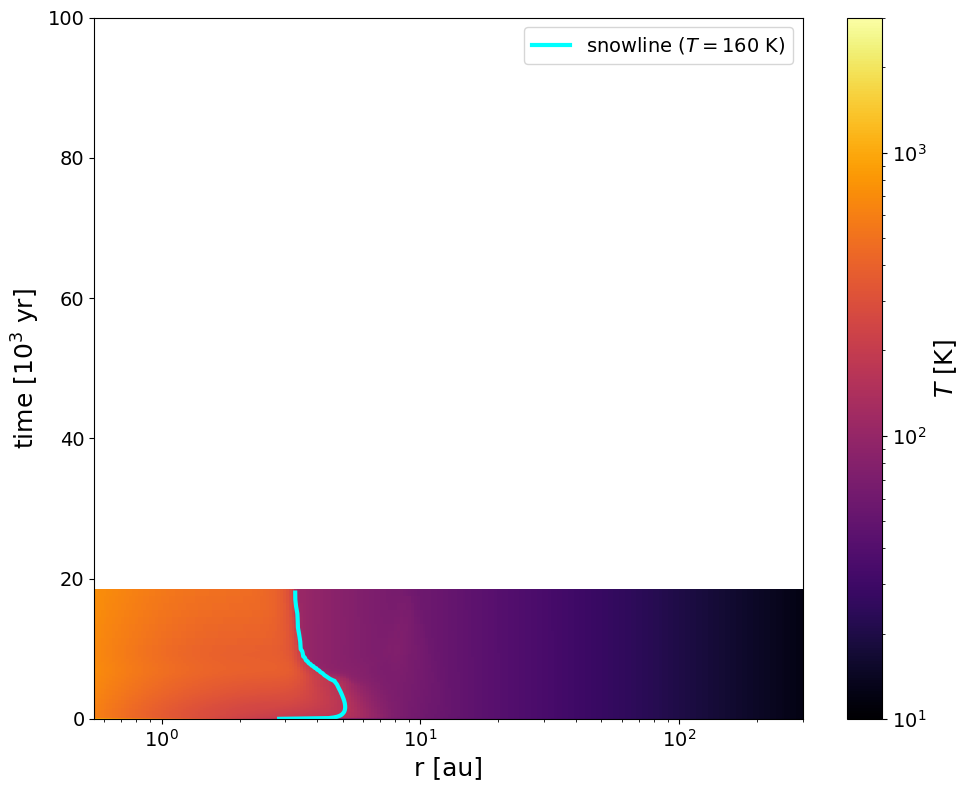

In [3]:
# [旧 cell 39]
# ======================================================
# 中心面温度 T の (r,t) 時空図 + スノーライン(T=160K)
# file_gas 列: 0:r_cen 12:T
# ======================================================

AU = 1.495979e+13

outdir = BASE_DIR
resultdir = MODEL
t_start = 0

path_gas = outdir + resultdir
years = list_years(path_gas, t_start)

T_rt, r_snow = [], []
for year in years:
    gas = np.loadtxt(path_gas + "/out{}_gas".format(year), usecols=(0, 12))
    r, T = gas[:, 0], gas[:, 1]
    T_rt.append(T)

    r_snow.append(find_snowline(r, T))

t = np.array(years) / 1.0e3
r_au = r / AU
T_rt = np.array(T_rt)

fig, ax = plt.subplots(figsize=(10, 8))
pc = ax.pcolormesh(r_au, t, T_rt, cmap="inferno", norm=LogNorm(vmin=10.0, vmax=3000.0), shading="nearest", rasterized=True)
cb = fig.colorbar(pc, ax=ax)
cb.set_label(r"$T$ [K]", fontsize=18)
cb.ax.tick_params(labelsize=14)

ax.plot(r_snow, t, color="cyan", lw=3, label=r"snowline ($T = {:.0f}$ K)".format(T_snow))

ax.set_xscale("log")
ax.set_xlabel("r [au]", fontsize=18)
ax.set_ylabel(r"time [$10^3$ yr]", fontsize=18)
ax.set_xlim((r_min, r_max))
ax.set_ylim((t_min, t_max))
# ax.set_title(model_names[resultdir] + r" : midplane temperature", fontsize=14)
ax.tick_params(labelsize=14)
ax.legend(fontsize=14, loc="upper right")
plt.tight_layout()
plt.savefig(fig_path("snowline.png", root=ANALYSIS_FIG_DIR))
plt.show()

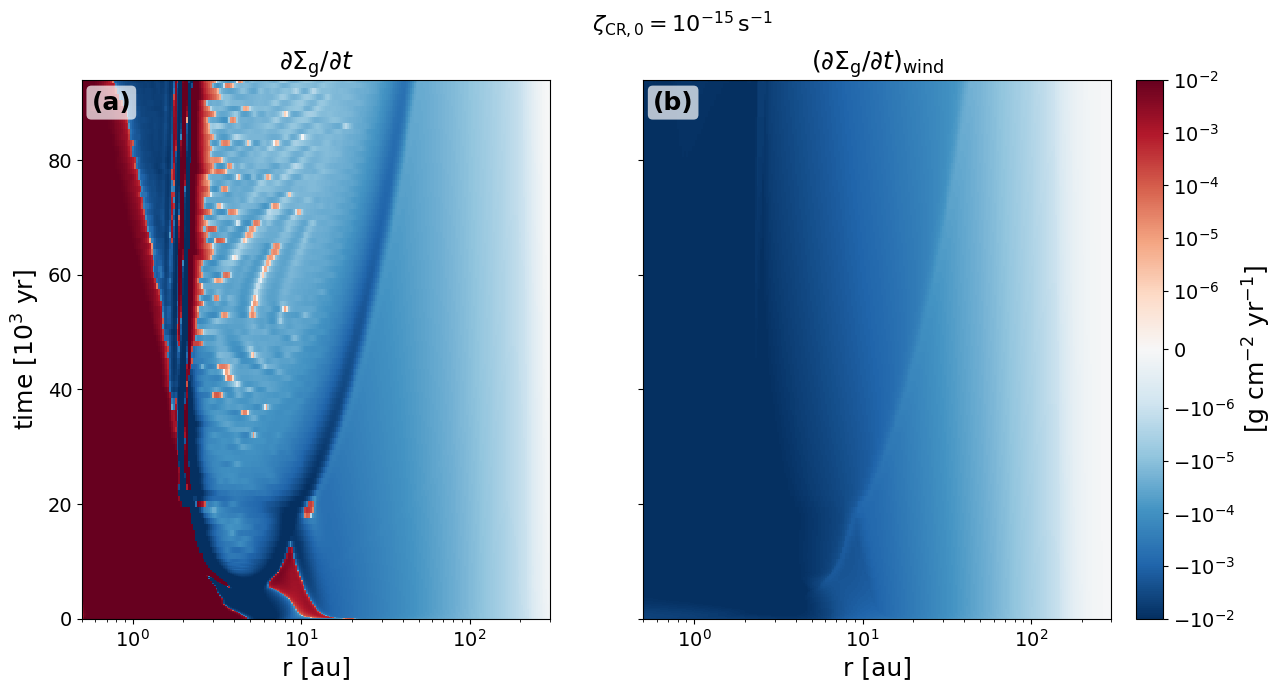

In [4]:
# [旧 cell 40]
# ======================================================
# dSigma_g/dt と (dSigma_g/dt)_wind の (r,t) 時空図 (1x2 ミニマップ)
# dSigma_g/dt        : コードの更新式 (CalcGasFlux) と同じ形で速度から計算
#   dSigma_g/dt = -2 (r_bod[i+1] F[i+1] - r_bod[i] F[i]) / (r_bod[i+1]^2 - r_bod[i]^2) - dsigmagdt_w
#   面速度 v_bod は sqrt(Sigma_g) 重みの Roe 平均, F は風上 (境界は流出のみ)
# (dSigma_g/dt)_wind : -dsigmagdt_w  (コードでは sigmag -= dsigmagdt_w*dt)
# file_gas 列: 0:r_cen 1:sigmag 4:vg_r 11:dsigmagdt_w
# 単位は g cm^-2 yr^-1, 色は SymLogNorm (赤: 増加, 青: 減少)
# ======================================================

AU = 1.495979e+13
yr = 3.155760e+07

outdir = BASE_DIR
resultdir = MODEL
t_start = 0
rate_max = 1.0e-2     # カラーバーの範囲 [g cm^-2 yr^-1]
rate_lin = 1.0e-6     # |rate| < rate_lin は線形

path_gas = outdir + resultdir
years = list_years(path_gas)

def calc_dSdt(r, sig, vgr, dsdt_w):
    # log grid: r_cen = sqrt(r_bod[i]*r_bod[i+1])
    q = r[1] / r[0]
    r_bod = np.append(r / np.sqrt(q), r[-1] * np.sqrt(q))
    n = len(r)
    v_bod = np.empty(n + 1)
    w = np.sqrt(sig[1:]) / (np.sqrt(sig[1:]) + np.sqrt(sig[:-1]))
    v_bod[1:n] = w * vgr[1:] + (1.0 - w) * vgr[:-1]
    v_bod[0], v_bod[n] = vgr[0], vgr[-1]
    F = np.empty(n + 1)
    F[1:n] = np.where(v_bod[1:n] >= 0.0, v_bod[1:n] * sig[:-1], v_bod[1:n] * sig[1:])
    F[0] = v_bod[0] * sig[0] if v_bod[0] < 0.0 else 0.0
    F[n] = v_bod[n] * sig[-1] if v_bod[n] > 0.0 else 0.0
    rF = r_bod * F
    return -2.0 * (rF[1:] - rF[:-1]) / (r_bod[1:]**2 - r_bod[:-1]**2) - dsdt_w

dSdt, dSdt_wind = [], []
for year in years:
    gas = np.loadtxt(path_gas + "/out{}_gas".format(year), usecols=(0, 1, 4, 11))
    r, sig, vgr, dsdt_w = gas[:, 0], gas[:, 1], gas[:, 2], gas[:, 3]
    dSdt.append(calc_dSdt(r, sig, vgr, dsdt_w) * yr)
    dSdt_wind.append(-dsdt_w * yr)

t_yr = np.array(years, dtype=float)
dSdt = np.array(dSdt)
dSdt_wind = np.array(dSdt_wind)

sel = t_yr >= t_start
t = t_yr[sel] / 1.0e3

# t_min = t[0]
r_au = r / AU
norm = SymLogNorm(linthresh=rate_lin, vmin=-rate_max, vmax=rate_max, base=10)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
panels = [(dSdt[sel], r"$\partial \Sigma_{\rm g}/\partial t$"),
          (dSdt_wind[sel], r"$(\partial \Sigma_{\rm g}/\partial t)_{\rm wind}$")]
for ax, (data, title) in zip(axes, panels):
    pc = ax.pcolormesh(r_au, t, data, cmap="RdBu_r", norm=norm, shading="nearest", rasterized=True)
    ax.set_xscale("log")
    ax.set_xlabel("r [au]", fontsize=18)
    ax.set_xlim((r_min, r_max))
    ax.set_ylim((t_min, t_max))
    ax.set_title(title, fontsize=18)
    ax.tick_params(labelsize=14)
axes[0].set_ylabel(r"time [$10^3$ yr]", fontsize=18)

cb = fig.colorbar(pc, ax=axes, pad=0.02)
cb.set_label(r"[g cm$^{-2}$ yr$^{-1}$]", fontsize=18)
cb.ax.tick_params(labelsize=14)
fig.suptitle(model_names[resultdir], fontsize=16)
plt.show()

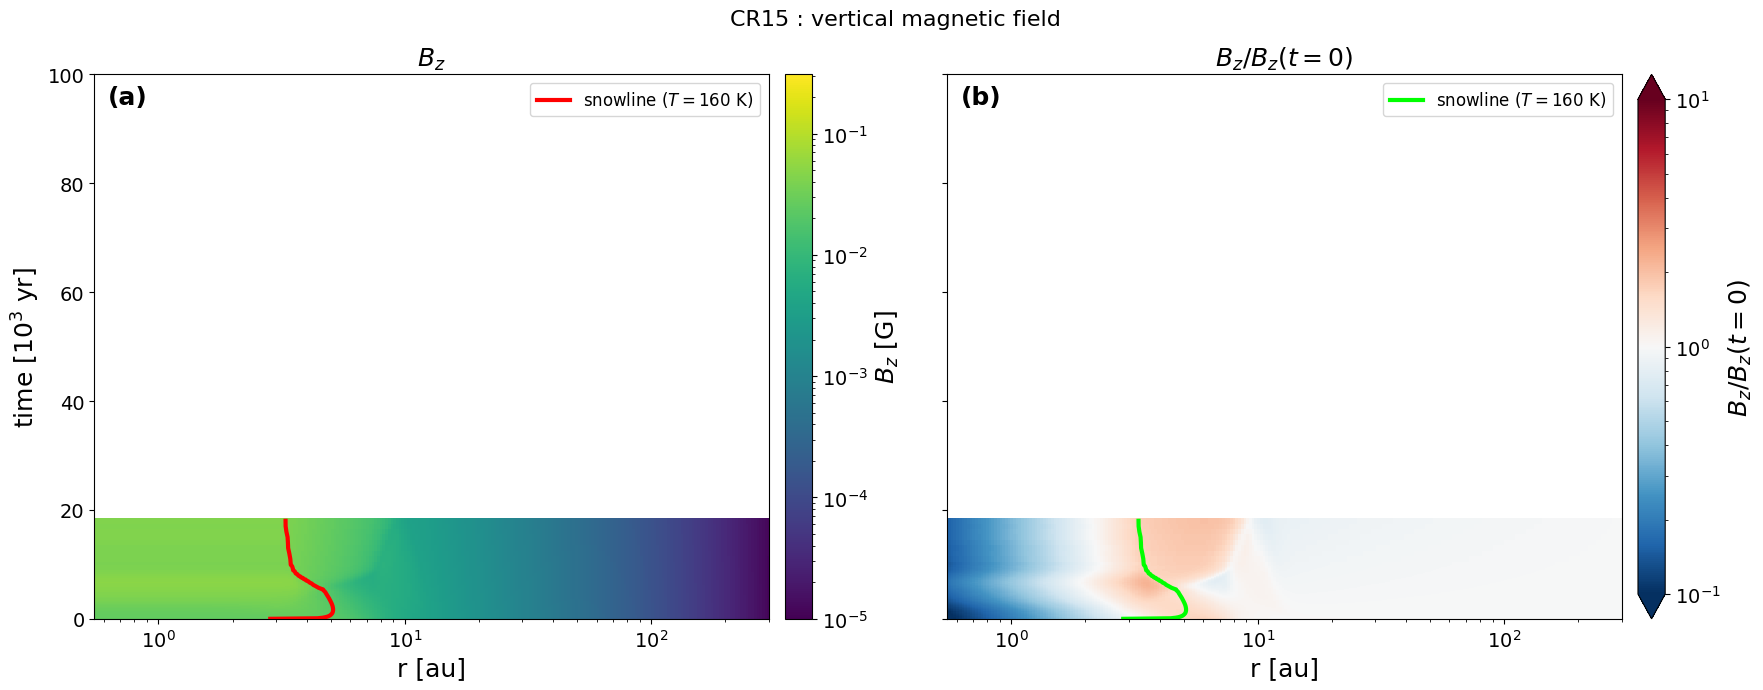

In [4]:
# [旧 cell 41]
# ======================================================
# 鉛直磁場 B_z と B_z/B_z(t=0) の (r,t) 時空図 (1x2 ミニマップ) + スノーライン(T=160K)
# file_gas 列: 0:r_cen 12:T     file_mag 列: 0:r_cen 2:B_z [G]
# ======================================================

AU = 1.495979e+13

outdir = BASE_DIR
resultdir = MODEL
t_start = 0
ratio_range = 10.0   # B_z/B_z(t=0) のカラーバー範囲 [1/ratio_range, ratio_range]

path_gas = outdir + resultdir
path_mag = outdir + resultdir + "_B"
years = list_years(path_gas, t_start, path_mag=path_mag)

B_rt, r_snow = [], []
for year in years:
    gas = np.loadtxt(path_gas + "/out{}_gas".format(year), usecols=(0, 12))
    r, T = gas[:, 0], gas[:, 1]
    B_rt.append(np.loadtxt(path_mag + "/out{}_B".format(year), usecols=(2,)))

    r_snow.append(find_snowline(r, T))

t = np.array(years) / 1.0e3
r_au = r / AU
B_rt = np.array(B_rt)

B0 = np.loadtxt(path_mag + "/out0_B", usecols=(2,))

fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True)
panels = [(B_rt, "viridis", LogNorm(), r"$B_z$ [G]", r"$B_z$"),
          (B_rt / B0, "RdBu_r", LogNorm(vmin=1.0 / ratio_range, vmax=ratio_range),
           r"$B_z/B_z(t=0)$", r"$B_z/B_z(t=0)$")]
for ax, (data, cmap, norm, cb_label, title) in zip(axes, panels):
    pc = ax.pcolormesh(r_au, t, data, cmap=cmap, norm=norm, shading="nearest", rasterized=True)
    cb = fig.colorbar(pc, ax=ax, pad=0.02, extend="both" if cmap == "RdBu_r" else "neither")
    cb.set_label(cb_label, fontsize=18)
    cb.ax.tick_params(labelsize=14)
    ax.plot(r_snow, t, color="red" if cmap == "viridis" else "lime", lw=3,
            label=r"snowline ($T = {:.0f}$ K)".format(T_snow))
    ax.set_xscale("log")
    ax.set_xlabel("r [au]", fontsize=18)
    ax.set_xlim((r_min, r_max))
    ax.set_ylim((t_min, t_max))
    ax.set_title(title, fontsize=18)
    ax.tick_params(labelsize=14)
    ax.legend(fontsize=12, loc="upper right")
axes[0].set_ylabel(r"time [$10^3$ yr]", fontsize=18)
fig.suptitle(model_names[resultdir] + " : vertical magnetic field", fontsize=16)
plt.tight_layout()
plt.show()

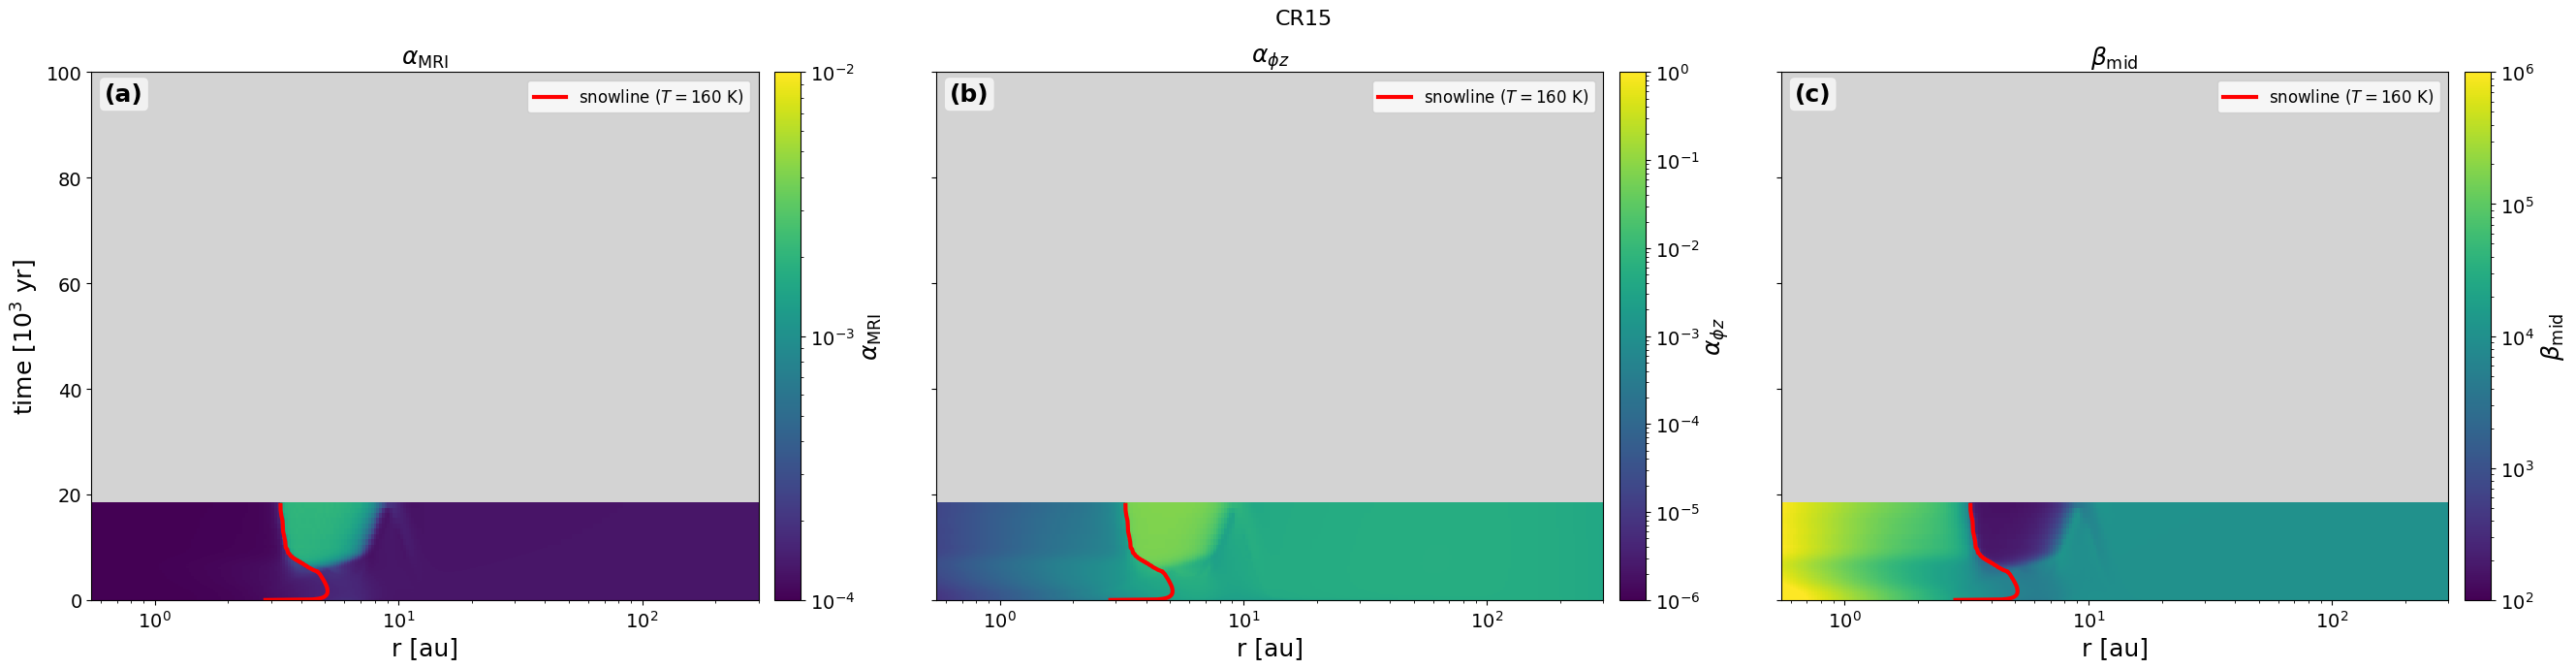

In [5]:
# [旧 cell 42]
# ======================================================
# alpha_MRI, alpha_phiz (= 0.75 sqrt(2 pi) (H_g/r) alpha_DW, コードの alpha_phiz), 中心面プラズマ beta の (r,t) 時空図 (1x3 ミニマップ) + スノーライン(T=160K)
# file_gas 列: 0:r_cen 12:T 17:alpha_phiz  (24:alpha_DW は使わない)     file_mag 列: 1:alpha_MRI 5:beta_mid
# alpha_phiz = 0 (活性層なし) のセルは灰色
# ======================================================

AU = 1.495979e+13

outdir = BASE_DIR
resultdir = MODEL
t_start = 0

path_gas = outdir + resultdir
path_mag = outdir + resultdir + "_B"
years = list_years(path_gas, t_start, path_mag=path_mag)

alpha_MRI, alpha_phiz, beta_mid, r_snow = [], [], [], []
for year in years:
    gas = np.loadtxt(path_gas + "/out{}_gas".format(year), usecols=(0, 12, 17))
    r, T = gas[:, 0], gas[:, 1]
    alpha_phiz.append(np.where(gas[:, 2] > 0.0, gas[:, 2], np.nan))
    mag = np.loadtxt(path_mag + "/out{}_B".format(year), usecols=(1, 5))
    alpha_MRI.append(mag[:, 0])
    beta_mid.append(mag[:, 1])

    r_snow.append(find_snowline(r, T))

t = np.array(years) / 1.0e3
r_au = r / AU

fig, axes = plt.subplots(1, 3, figsize=(27, 7), sharey=True)
panels = [(np.array(alpha_MRI), r"$\alpha_{\rm MRI}$", LogNorm(vmin=1.0e-4, vmax=1.0e-2)),
          (np.array(alpha_phiz), r"$\alpha_{\phi z}$", LogNorm(vmin=1.0e-6, vmax=1.0e0)),
          (np.array(beta_mid), r"$\beta_{\rm mid}$", LogNorm(vmin=1.0e2, vmax=1.0e6))]
for ax, (data, label, norm) in zip(axes, panels):
    ax.set_facecolor("lightgray")
    pc = ax.pcolormesh(r_au, t, data, cmap="viridis", norm=norm, shading="nearest", rasterized=True)
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.set_label(label, fontsize=18)
    cb.ax.tick_params(labelsize=14)
    ax.plot(r_snow, t, color="red", lw=3, label=r"snowline ($T = {:.0f}$ K)".format(T_snow))
    ax.set_xscale("log")
    ax.set_xlabel("r [au]", fontsize=18)
    ax.set_xlim((r_min, r_max))
    ax.set_ylim((t_min, t_max))
    ax.set_title(label, fontsize=18)
    ax.tick_params(labelsize=14)
    ax.legend(fontsize=12, loc="upper right")
axes[0].set_ylabel(r"time [$10^3$ yr]", fontsize=18)
fig.suptitle(model_names[resultdir], fontsize=16)
plt.tight_layout()
# plt.savefig(fig_path("alpha.png", root=ANALYSIS_FIG_DIR))
plt.show()

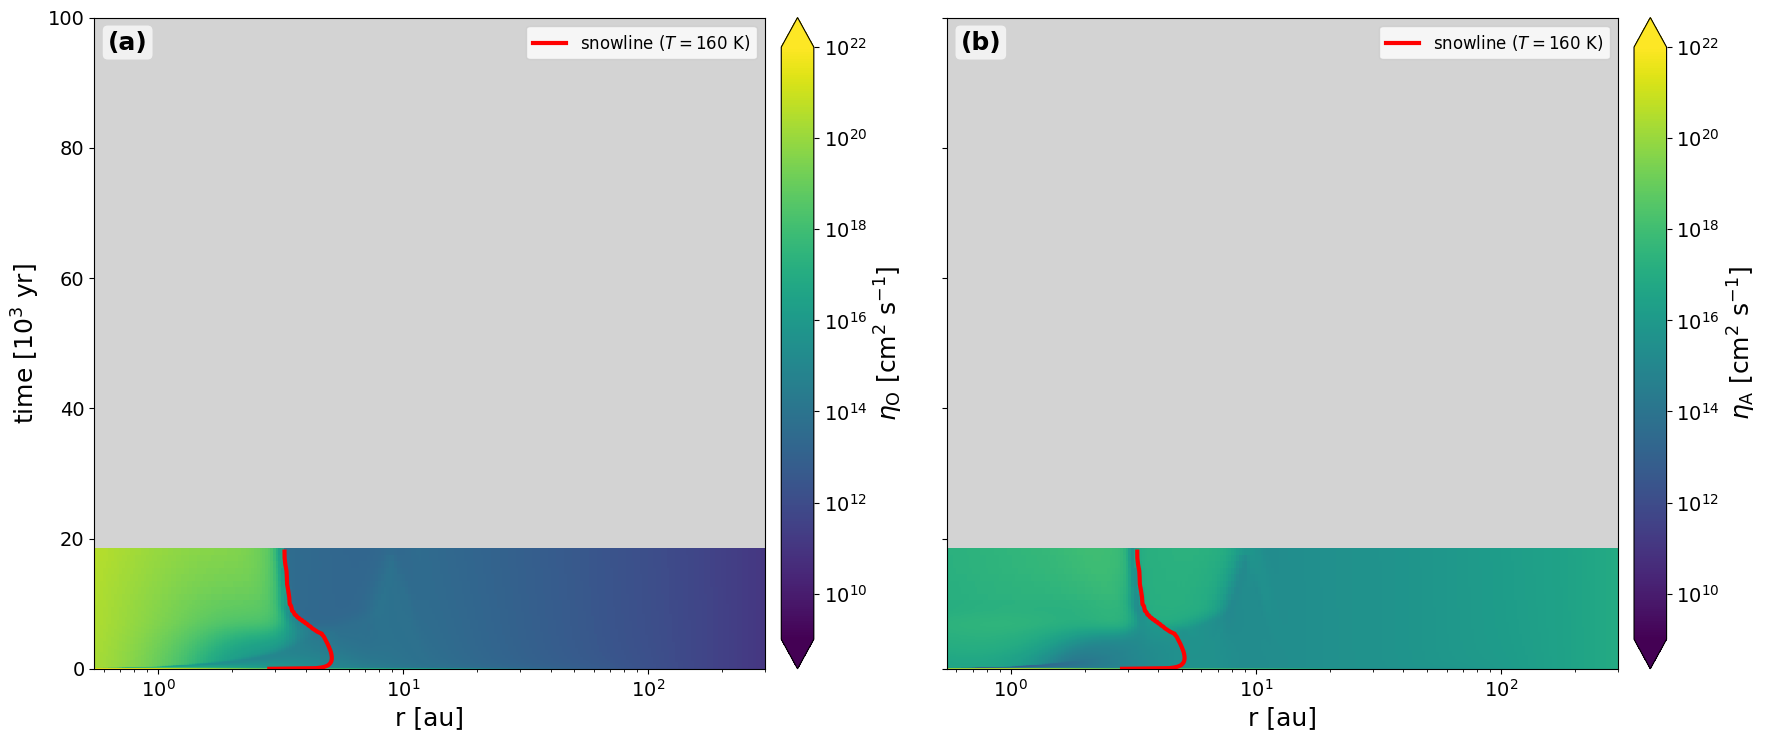

In [6]:
# [旧 cell 43]
# ======================================================
# オーム散逸 eta_O ・ 両極性拡散 eta_A の (r,t) 時空図 (1x2 ミニマップ) + スノーライン(T=160K)
# eta_O, eta_A は file_mag の鉛直(圧力重み)平均値
# file_gas 列: 0:r_cen 12:T     file_mag 列: 3:etaO_R 4:etaA_R
# ======================================================

AU = 1.495979e+13

outdir = BASE_DIR
resultdir = MODEL
t_start = 0
eta_range = (1.0e9, 1.0e22)       # eta のカラーバー範囲 [cm^2 s^-1] (eta_O, eta_A 共通)

path_gas = outdir + resultdir
path_mag = outdir + resultdir + "_B"
years = list_years(path_gas, t_start, path_mag=path_mag)

eta_O, eta_A, r_snow = [], [], []
for year in years:
    gas = np.loadtxt(path_gas + "/out{}_gas".format(year), usecols=(0, 12))
    mag = np.loadtxt(path_mag + "/out{}_B".format(year), usecols=(3, 4))
    r, T = gas[:, 0], gas[:, 1]
    eta_O.append(mag[:, 0])
    eta_A.append(mag[:, 1])

    r_snow.append(find_snowline(r, T))

t = np.array(years) / 1.0e3
r_au = r / AU
panels = [(np.array(eta_O), r"$\eta_{\rm O}$ [cm$^2$ s$^{-1}$]", r"Ohmic diffusivity $\eta_{\rm O}$"),
          (np.array(eta_A), r"$\eta_{\rm A}$ [cm$^2$ s$^{-1}$]", r"Ambipolar diffusivity $\eta_{\rm A}$")]

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5), sharex=True, sharey=True)
for ax, (data, cb_label, title) in zip(axes, panels):
    ax.set_facecolor("lightgray")
    pc = ax.pcolormesh(r_au, t, data, cmap="viridis", norm=LogNorm(vmin=eta_range[0], vmax=eta_range[1]),
                       shading="nearest", rasterized=True)
    cb = fig.colorbar(pc, ax=ax, pad=0.02, extend="both")
    cb.set_label(cb_label, fontsize=18)
    cb.ax.tick_params(labelsize=14)
    ax.plot(r_snow, t, color="red", lw=3)
    ax.set_xscale("log")
    ax.set_xlim((r_min, r_max))
    ax.set_ylim((t_min, t_max))
    ax.set_xlabel("r [au]", fontsize=18)
    # ax.set_title(title, fontsize=18)
    ax.tick_params(labelsize=14)
    ax.legend(handles=[Line2D([], [], color="red", lw=3, label=r"snowline ($T = {:.0f}$ K)".format(T_snow))],
              fontsize=12, loc="upper right")
axes[0].set_ylabel(r"time [$10^3$ yr]", fontsize=18)
# fig.suptitle(model_names[resultdir], fontsize=16)
plt.tight_layout()
# plt.savefig(fig_path("eta.png", root=ANALYSIS_FIG_DIR))
plt.show()

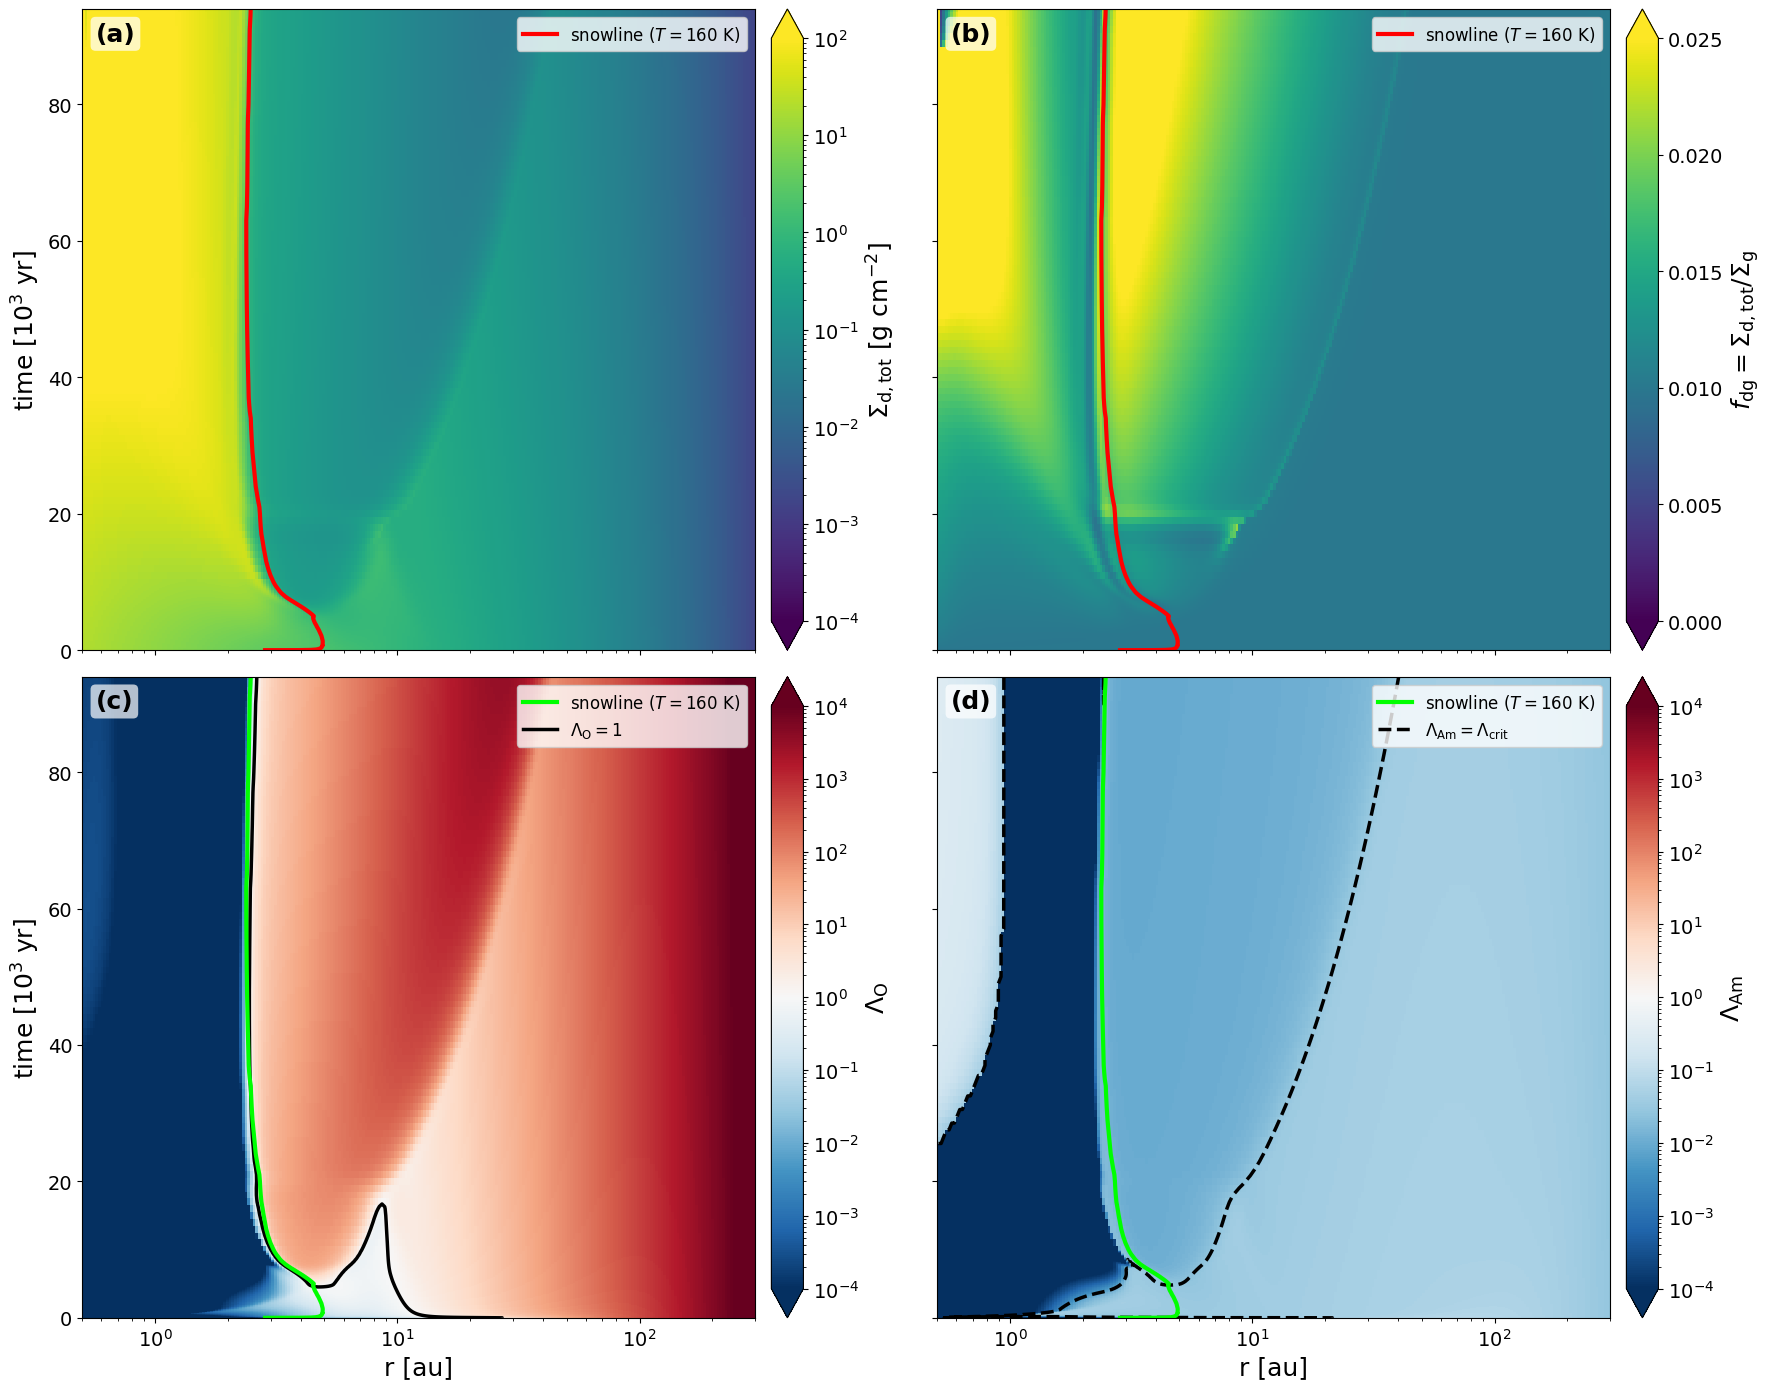

In [8]:
# [旧 cell 44]
# ======================================================
# Sigma_d,tot ・ f_dg ・ Lambda_O ・ Lambda_A の (r,t) 時空図 (2x2 ミニマップ) + スノーライン(T=160K)
# f_dg = Sigma_d,tot/Sigma_g (全サイズ合計)
# Lambda_O = v_A^2/(eta_O Omega) , Lambda_A = v_A^2/(eta_A Omega)
#   v_A^2 = B^2/(4 pi rho_mid) , rho_mid = Sigma_g/(sqrt(2 pi) H_g) , H_g = c_s/Omega , Omega = sqrt(G M_sun/r^3)
#   eta_O, eta_A は file_mag の鉛直(圧力重み)平均値
# Lambda_crit : Bai & Stone (2011) の MRI 条件 beta_min(Am) = beta_mid を満たす Am (コードの Newton_Am と同じ式)
#   beta_min(Am) = sqrt( (50 Am^-1.2)^2 + (8 Am^-0.3 + 1)^2 )
# file_gas 列: 0:r_cen 1:sigmag 2:sigmad_tot 12:T     file_mag 列: 2:B_z 3:etaO_R 4:etaA_R 5:beta_mid
# Lambda は Lambda = 1 を白(中央)とし, 黒実線が Lambda_O = 1, 黒破線が Lambda_A = Lambda_crit
# ======================================================
from matplotlib.colors import LogNorm, Normalize

AU = 1.495979e+13
G = 6.67408e-08
Msolar = 1.989000e+33
kB = 1.38064852e-16
mH = 1.67353e-24
mu = 2.34

outdir = BASE_DIR
resultdir = MODEL
t_start = 0
sigmad_range = (1.0e-4, 1.0e2)    # Sigma_d,tot のカラーバー範囲 [g cm^-2]
fdg_range = (0.0, 2.5e-2)         # f_dg のカラーバー範囲 (線形)
plot_LambdaO_1 = True             # True: Lambda_O = 1 の線を描く
plot_LambdaAm_crit = True         # True: Lambda_Am = Lambda_crit の線を描く
lambda_range = 1.0e4              # Lambda のカラーバー範囲 [1/lambda_range, lambda_range]

def calc_Am_crit(beta):
    # beta_min(Am) は Am について単調減少 -> log(Am) で二分法. beta <= 1 は解なし (nan)
    beta = np.asarray(beta, dtype=float)
    beta_min = lambda Am: np.sqrt((50.0 * Am**-1.2)**2 + (8.0 * Am**-0.3 + 1.0)**2)
    lo, hi = np.full(beta.shape, -10.0), np.full(beta.shape, 10.0)
    for _ in range(80):
        mid = 0.5 * (lo + hi)
        above = beta_min(10.0**mid) > beta
        lo, hi = np.where(above, mid, lo), np.where(above, hi, mid)
    Am = 10.0**(0.5 * (lo + hi))
    return np.where(beta > beta_min(1.0e10), Am, np.nan)

path_gas = outdir + resultdir
path_mag = outdir + resultdir + "_B"
years = list_years(path_gas, t_start, path_mag=path_mag)

sigmad_tot, fdg, Lambda_O, Lambda_A, Lambda_crit, r_snow = [], [], [], [], [], []
for year in years:
    gas = np.loadtxt(path_gas + "/out{}_gas".format(year), usecols=(0, 1, 2, 12))
    mag = np.loadtxt(path_mag + "/out{}_B".format(year), usecols=(2, 3, 4, 5))
    r, sigmag, sigmad, T = gas[:, 0], gas[:, 1], gas[:, 2], gas[:, 3]
    B, etaO, etaA, beta_mid = mag[:, 0], mag[:, 1], mag[:, 2], mag[:, 3]

    omega = np.sqrt(G * Msolar / r**3)
    Hg = np.sqrt(kB * T / (mu * mH)) / omega
    rho_mid = sigmag / (np.sqrt(2.0 * np.pi) * Hg)
    VA_2 = B**2 / (4.0 * np.pi * rho_mid)

    sigmad_tot.append(np.where(sigmad > 0.0, sigmad, np.nan))
    fdg.append(np.where(sigmad > 0.0, sigmad / sigmag, np.nan))
    Lambda_O.append(VA_2 / (etaO * omega))
    Lambda_A.append(VA_2 / (etaA * omega))
    Lambda_crit.append(calc_Am_crit(beta_mid))

    r_snow.append(find_snowline(r, T))

t = np.array(years) / 1.0e3
r_au = r / AU
Lambda_O = np.array(Lambda_O)
Lambda_A = np.array(Lambda_A)
Lambda_crit = np.array(Lambda_crit)

lam_norm = lambda: LogNorm(vmin=1.0 / lambda_range, vmax=lambda_range)
panels = [(np.array(sigmad_tot), "viridis", LogNorm(vmin=sigmad_range[0], vmax=sigmad_range[1]),
           r"$\Sigma_{\rm d,tot}$ [g cm$^{-2}$]", r"$\Sigma_{\rm d,tot}$", "red", None),
          (np.array(fdg), "viridis", Normalize(vmin=fdg_range[0], vmax=fdg_range[1]),
           r"$f_{\rm dg} = \Sigma_{\rm d,tot}/\Sigma_{\rm g}$", r"$f_{\rm dg}$", "red", None),
          (Lambda_O, "RdBu_r", lam_norm(), r"$\Lambda_{\rm O}$", r"$\Lambda_{\rm O}$", "lime",
           (np.log10(Lambda_O), "solid", r"$\Lambda_{\rm O} = 1$") if plot_LambdaO_1 else None),
          (Lambda_A, "RdBu_r", lam_norm(), r"$\Lambda_{\rm Am}$", r"$\Lambda_{\rm Am}$", "lime",
           (np.log10(Lambda_A / Lambda_crit), "dashed", r"$\Lambda_{\rm Am} = \Lambda_{\rm crit}$") if plot_LambdaAm_crit else None)]

fig, axes = plt.subplots(2, 2, figsize=(18, 14), sharex=True, sharey=True)
for ax, (data, cmap, norm, cb_label, title, c_snow, contour) in zip(axes.flat, panels):
    ax.set_facecolor("lightgray")
    pc = ax.pcolormesh(r_au, t, data, cmap=cmap, norm=norm, shading="nearest", rasterized=True)
    cb = fig.colorbar(pc, ax=ax, pad=0.02, extend="both")
    cb.set_label(cb_label, fontsize=18)
    cb.ax.tick_params(labelsize=14)
    handles = [Line2D([], [], color=c_snow, lw=3, label=r"snowline ($T = {:.0f}$ K)".format(T_snow))]
    if contour is not None:
        c_data, c_ls, c_label = contour
        ax.contour(r_au, t, c_data, levels=[0.0], colors="black", linewidths=2.5, linestyles=c_ls)
        handles.append(Line2D([], [], color="black", lw=2.5, linestyle=c_ls, label=c_label))
    ax.plot(r_snow, t, color=c_snow, lw=3)
    ax.set_xscale("log")
    ax.set_xlim((r_min, r_max))
    ax.set_ylim((t_min, t_max))
    # ax.set_title(title, fontsize=18)
    ax.tick_params(labelsize=14)
    ax.legend(handles=handles, fontsize=12, loc="upper right")
for ax in axes[1, :]:
    ax.set_xlabel("r [au]", fontsize=18)
for ax in axes[:, 0]:
    ax.set_ylabel(r"time [$10^3$ yr]", fontsize=18)
# fig.suptitle(model_names[resultdir], fontsize=16)
plt.tight_layout()
# plt.savefig(fig_path("Lambda.png", root=ANALYSIS_FIG_DIR))
plt.show()

## 磁場の時間変化と輸送

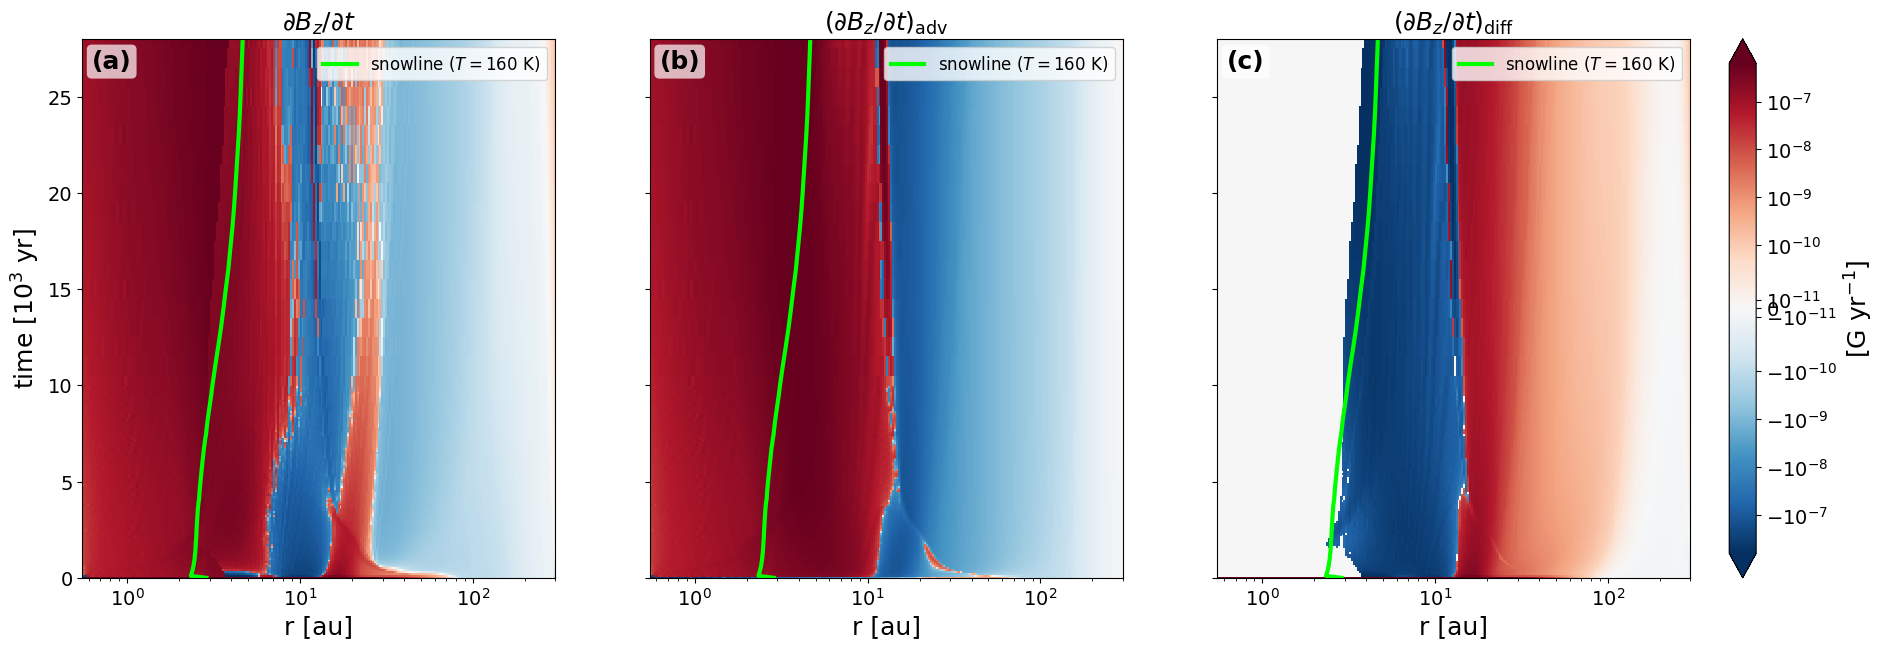

In [20]:
# [旧 cell 55]
# ======================================================
# dB_z/dt (誘導方程式の瞬間値) と その移流項・拡散項 の (r,t) 時空図 (1x3 ミニマップ) + スノーライン(T=160K)
# コード (magnetic_field1D.cpp Calc_Mag / Calc_Mag_Implicit) の更新式と同じ離散化のフラックス形式 (符号は外向きを正とする物理的な定義):
#   dB/dt = -2 (r_bod[i+1] F[i+1] - r_bod[i] F[i]) / (r_bod[i+1]^2 - r_bod[i]^2) ,  F = F_adv + F_diff
#   F_adv  = v_bod B_bod                        (B_bod, v_bod は sqrt(Sigma_g) 重みの Roe 平均)
#   F_diff = -eta_bod dB/dr|_bod                (eta_bod も Roe 平均, dB/dr は cff_R_Half の3点 (B[i], B_bod[i], B[i-1]))
#   eta_tot = min(etaO_R + etaA_R, eta_max)     (use_eta_cap = True: コードと同じ. eta_max は input から読む)
#   eta_tot = etaO_R + etaA_R                   (use_eta_cap = False: 上限なしの仮の評価. コードは常に eta_max で上限をかける)
#   どちらも use_eta_floor = false (Elsasser 数の下限なし) のとき
#   境界: F_diff = 0 (両端), F_adv は流出のみ (内側 F_adv < 0, 外側 F_adv > 0)
# file_gas 列: 0:r_cen 1:sigmag 4:vg_r 12:T     file_mag 列: 2:B_z 3:etaO_R 4:etaA_R
# 出力の B は有効数字7桁 (相対丸め誤差 ~5e-7) なので, eta が大きい (デッドゾーン) と F_diff が丸め誤差で決まってしまう.
#   丸め誤差から見積もった誤差 err_diff より |拡散項| が小さいセルは拡散項 = 0 とし, 合計 = 移流項 + 拡散項 (灰色にしない)
# 単位は G yr^-1, 色は SymLogNorm (赤: 増加, 青: 減少)
# ======================================================

AU = 1.495979e+13
yr = 3.155760e+07

outdir = BASE_DIR
resultdir = MODEL
t_start = 0
rate_max = None    # カラーバーの範囲 [G yr^-1]. None なら |dB/dt| の 99 パーセンタイル
rate_lin = None    # |rate| < rate_lin は線形. None なら rate_max * 1e-4
B_round = 1.0e-5   # 出力 B の相対丸め誤差 (%e, 小数6桁)
use_eta_cap = True   # True: eta_tot を eta_max (input) で上限 (コードと同じ), False: 上限なし

path_gas = outdir + resultdir
path_mag = outdir + resultdir + "_B"
years = list_years(path_gas, t_start, path_mag=path_mag)

# eta_max は計算時の input から読む
eta_max = 1.0e20
with open(path_gas + "/input") as f:
    for line in f:
        if line.split("//")[0].split("=")[0].strip() == "eta_max":
            eta_max = float(line.split("//")[0].split("=")[1])

def calc_dBdt(r, sig, vgr, B, eta):
    # log grid: r_cen = sqrt(r_bod[i]*r_bod[i+1])
    q = r[1] / r[0]
    r_bod = np.append(r / np.sqrt(q), r[-1] * np.sqrt(q))
    n = len(r)
    # 内部面 (1..n-1) の Roe 平均
    w = np.sqrt(sig[1:]) / (np.sqrt(sig[1:]) + np.sqrt(sig[:-1]))
    v_bod = np.empty(n + 1)
    v_bod[1:n] = w * vgr[1:] + (1.0 - w) * vgr[:-1]
    v_bod[0], v_bod[n] = vgr[0], vgr[-1]
    B_bod = np.empty(n + 1)
    B_bod[1:n] = w * B[1:] + (1.0 - w) * B[:-1]
    B_bod[0], B_bod[n] = B[0], B[-1]          # ghost は zero-gradient
    eta_bod = w * eta[1:] + (1.0 - w) * eta[:-1]
    # cff_R_Half: s = r_bod[i] - r_cen[i-1], t = r_cen[i] - r_bod[i]
    s = r_bod[1:n] - r[:-1]
    t = r[1:] - r_bod[1:n]
    dBdr = (s*s * B[1:] + (t*t - s*s) * B_bod[1:n] - t*t * B[:-1]) / (s * t * (s + t))
    dBdr = np.where(B[1:] == B[:-1], 0.0, dBdr)

    F_adv = v_bod * B_bod
    F_adv[0] = min(F_adv[0], 0.0)
    F_adv[n] = max(F_adv[n], 0.0)
    F_diff = np.zeros(n + 1)
    F_diff[1:n] = -eta_bod * dBdr

    # 丸め誤差による F_diff の誤差 (dB/dr の3点式の係数の絶対値で評価)
    dB = B_round * np.abs(B)
    err_F = np.zeros(n + 1)
    err_F[1:n] = eta_bod * (s*s * dB[1:] + np.abs(t*t - s*s) * (w * dB[1:] + (1.0 - w) * dB[:-1])
                            + t*t * dB[:-1]) / (s * t * (s + t))

    def div(F):
        rF = r_bod * F
        return -2.0 * (rF[1:] - rF[:-1]) / (r_bod[1:]**2 - r_bod[:-1]**2)
    err_diff = 2.0 * (r_bod[1:] * err_F[1:] + r_bod[:-1] * err_F[:-1]) / (r_bod[1:]**2 - r_bod[:-1]**2)
    return div(F_adv), div(F_diff), err_diff

dBdt_adv, dBdt_diff, err_diff, r_snow = [], [], [], []
for year in years:
    gas = np.loadtxt(path_gas + "/out{}_gas".format(year), usecols=(0, 1, 4, 12))
    r, sig, vgr, T = gas.T
    mag = np.loadtxt(path_mag + "/out{}_B".format(year), usecols=(2, 3, 4))
    B, etaO, etaA = mag.T
    eta = np.minimum(etaO + etaA, eta_max) if use_eta_cap else etaO + etaA
    a, d, e = calc_dBdt(r, sig, vgr, B, eta)
    dBdt_adv.append(a * yr)
    dBdt_diff.append(d * yr)
    err_diff.append(e * yr)

    r_snow.append(find_snowline(r, T))

dBdt_adv = np.array(dBdt_adv)
dBdt_diff = np.array(dBdt_diff)
err_diff = np.array(err_diff)
dBdt_diff = np.where(np.abs(dBdt_diff) > err_diff, dBdt_diff, 0.0)
dBdt = dBdt_adv + dBdt_diff

t = np.array(years) / 1.0e3
r_au = r / AU
if rate_max is None:
    rate_max = np.nanpercentile(np.abs(dBdt_adv), 99)
if rate_lin is None:
    rate_lin = rate_max * 1.0e-4
norm = SymLogNorm(linthresh=rate_lin, vmin=-rate_max, vmax=rate_max, base=10)

fig, axes = plt.subplots(1, 3, figsize=(25, 7), sharey=True)
panels = [(dBdt, r"$\partial B_z/\partial t$"),
          (dBdt_adv, r"$(\partial B_z/\partial t)_{\rm adv}$"),
          (dBdt_diff, r"$(\partial B_z/\partial t)_{\rm diff}$")]
for ax, (data, title) in zip(axes, panels):
    ax.set_facecolor("lightgray")
    pc = ax.pcolormesh(r_au, t, data, cmap="RdBu_r", norm=norm, shading="nearest", rasterized=True)
    ax.plot(r_snow, t, color="lime", lw=3, label=r"snowline ($T = {:.0f}$ K)".format(T_snow))
    ax.set_xscale("log")
    ax.set_xlabel("r [au]", fontsize=18)
    ax.set_xlim((r_min, r_max))
    ax.set_ylim((t[0], t[-1]))
    #ax.set_ylim(0.0, 1.0)
    # ax.set_ylim(0.0,0.1)
    ax.set_title(title, fontsize=18)
    ax.tick_params(labelsize=14)
    ax.legend(fontsize=12, loc="upper right")
axes[0].set_ylabel(r"time [$10^3$ yr]", fontsize=18)

cb = fig.colorbar(pc, ax=axes, pad=0.02, extend="both")
cb.set_label(r"[G yr$^{-1}$]", fontsize=18)
cb.ax.tick_params(labelsize=14)
eta_label = r" ($\eta_{{\rm tot}} \leq {:.0e}$ cm$^2$ s$^{{-1}}$)".format(eta_max) if use_eta_cap else r" ($\eta_{\rm tot}$ cap off)"
# fig.suptitle(model_names[resultdir] + " : induction equation" + eta_label, fontsize=16)
plt.show()

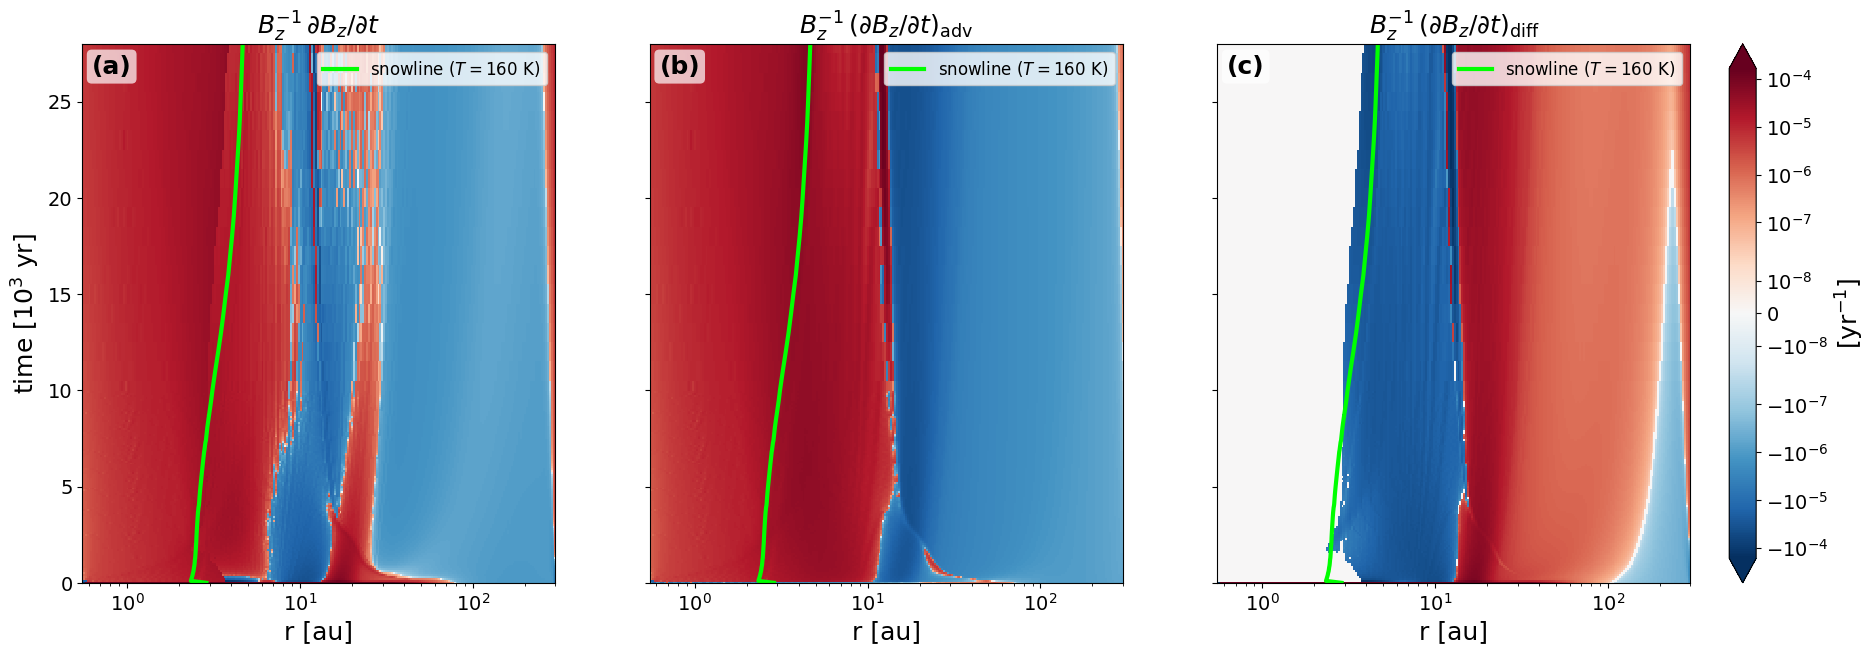

In [21]:
# [旧 cell 56]
# ======================================================
# (1/B_z) dB_z/dt と その移流項・拡散項 の (r,t) 時空図 (1x3 ミニマップ) + スノーライン(T=160K)
# 上のセル (dB_z/dt) の dBdt, dBdt_adv, dBdt_diff, years, r_snow, r_au, t を B_z で割ったもの
#   (1/B_z) dB_z/dt = (1/B_z)(dB_z/dt)_adv + (1/B_z)(dB_z/dt)_diff
# B_z は file_mag 列 2 を読み直す. B_z = 0 のセルは灰色 (NaN)
# 単位は yr^-1, 色は SymLogNorm (赤: 増加, 青: 減少)
# ======================================================

grate_max = None   # カラーバーの範囲 [yr^-1]. None なら |(1/B) dB/dt_adv| の 99 パーセンタイル
grate_lin = None   # |rate| < grate_lin は線形. None なら grate_max * 1e-4

B_all = np.array([np.loadtxt(path_mag + "/out{}_B".format(year), usecols=(2,)) for year in years])
B_inv = np.where(B_all != 0.0, 1.0 / np.where(B_all != 0.0, B_all, 1.0), np.nan)
gdBdt = dBdt * B_inv
gdBdt_adv = dBdt_adv * B_inv
gdBdt_diff = dBdt_diff * B_inv

if grate_max is None:
    grate_max = np.nanpercentile(np.abs(gdBdt_adv), 99)
if grate_lin is None:
    grate_lin = grate_max * 1.0e-4
norm = SymLogNorm(linthresh=grate_lin, vmin=-grate_max, vmax=grate_max, base=10)

fig, axes = plt.subplots(1, 3, figsize=(25, 7), sharey=True)
panels = [(gdBdt, r"$B_z^{-1}\,\partial B_z/\partial t$"),
          (gdBdt_adv, r"$B_z^{-1}\,(\partial B_z/\partial t)_{\rm adv}$"),
          (gdBdt_diff, r"$B_z^{-1}\,(\partial B_z/\partial t)_{\rm diff}$")]
for ax, (data, title) in zip(axes, panels):
    ax.set_facecolor("lightgray")
    pc = ax.pcolormesh(r_au, t, data, cmap="RdBu_r", norm=norm, shading="nearest", rasterized=True)
    ax.plot(r_snow, t, color="lime", lw=3, label=r"snowline ($T = {:.0f}$ K)".format(T_snow))
    ax.set_xscale("log")
    ax.set_xlabel("r [au]", fontsize=18)
    ax.set_xlim((r_min, r_max))
    # ax.set_ylim(0.0,0.1)
    ax.set_ylim((t[0], t[-1]))
    ax.set_title(title, fontsize=18)
    ax.tick_params(labelsize=14)
    ax.legend(fontsize=12, loc="upper right")
axes[0].set_ylabel(r"time [$10^3$ yr]", fontsize=18)

cb = fig.colorbar(pc, ax=axes, pad=0.02, extend="both")
cb.set_label(r"[yr$^{-1}$]", fontsize=18)
cb.ax.tick_params(labelsize=14)
plt.show()

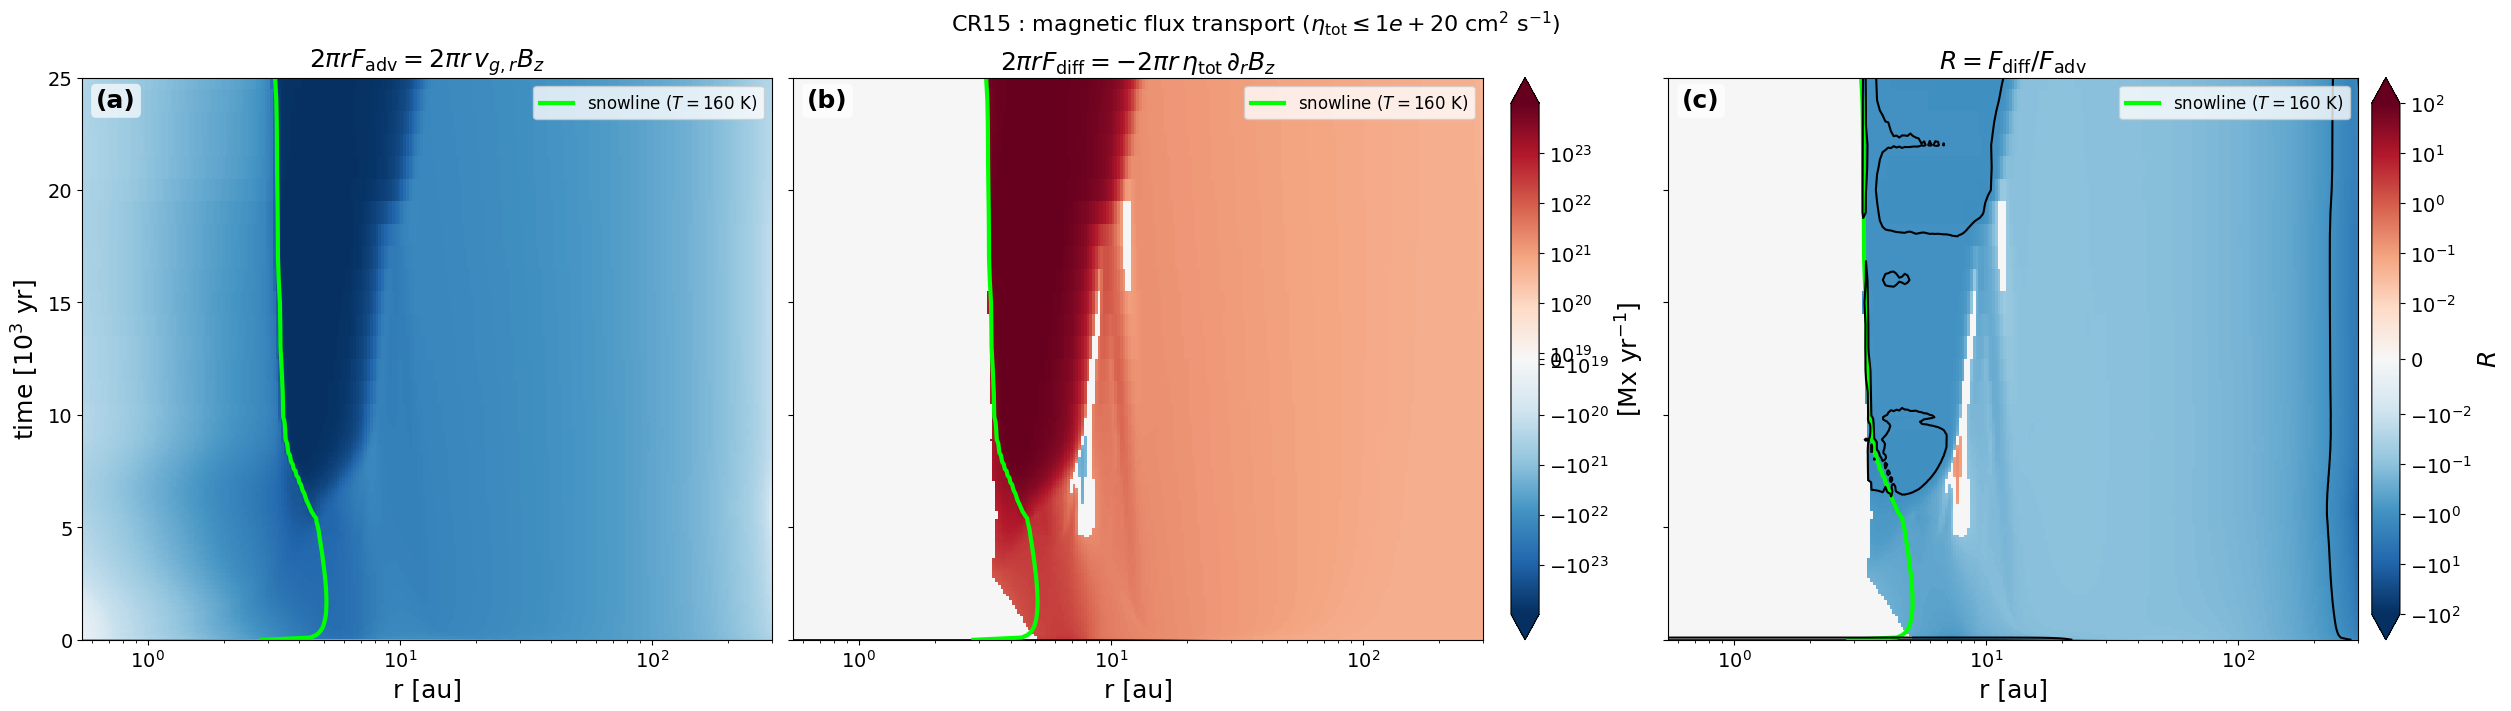

In [7]:
# [旧 cell 58]
# ======================================================
# 移流・拡散による磁束の輸送率 2 pi r F_adv, 2 pi r F_diff とその比 R の (r,t) 時空図 (1x3 ミニマップ) + スノーライン(T=160K)
# 誘導方程式 dB/dt = -(1/r) d/dr [ r (F_adv + F_diff) ] ,  F_adv = v_g B ,  F_diff = -eta dB/dr  (外向きが正)
#   を r の内側で積分すると, Phi(<r) = int 2 pi r B dr について dPhi(<r)/dt = -2 pi r (F_adv + F_diff)
#   2 pi r F_adv , 2 pi r F_diff : 半径 r を外向きに横切る磁束の輸送率 (正なら Phi(<r) が減る)
#   R = F_diff / F_adv  ( = v_diff/v_g * sign(B) ).  |R| > 1 なら拡散が優勢 (黒線: |R| = 1)
#   R > 0 : 移流と拡散が同じ向きに磁束を運ぶ, R < 0 : 逆向き
# F_adv, F_diff はコード (magnetic_field1D.cpp Calc_Mag) と同じ面上の値 (cell 55 の calc_dBdt と同じ再構成):
#   B_bod, v_bod, eta_bod は sqrt(Sigma_g) 重みの Roe 平均, dB/dr は cff_R_Half の3点 (B[i], B_bod[i], B[i-1])
#   内部面 (r_bod[1..n-1]) のみ描く (境界面は F_diff = 0)
# eta_tot = min(etaO_R + etaA_R, eta_max)   (use_eta_cap = True: コードと同じ. eta_max は input から読む)
# 変化率にはなましをかけない. R はそのままの値から計算する
# 出力の B は有効数字7桁 (相対丸め誤差 ~5e-7) なので, eta が大きいと F_diff が丸め誤差で決まってしまう.
#   丸め誤差から見積もった誤差より |2 pi r F_diff| が小さいセルは F_diff = 0 とする (そのセルは R = 0)
# file_gas 列: 0:r_cen 1:sigmag 4:vg_r 12:T     file_mag 列: 2:B_z 3:etaO_R 4:etaA_R
# 単位は Mx yr^-1 (= G cm^2 yr^-1), 色は SymLogNorm (赤: 正 = 外向きに磁束を運ぶ, 青: 負 = 内向き)
# ======================================================

AU = 1.495979e+13
yr = 3.155760e+07

outdir = BASE_DIR
resultdir = MODEL
t_start = 0
rate_max = None      # カラーバーの範囲 [Mx yr^-1]. None なら |(dPhi/dt)_adv|, |(dPhi/dt)_diff| の 99 パーセンタイル
rate_lin = None      # |rate| < rate_lin は線形. None なら rate_max * 1e-4
R_max, R_lin = 1.0e2, 1.0e-2   # R のカラーバーの範囲と線形領域
B_round = 1.0e-2     # 出力 B の相対丸め誤差 (%e, 小数6桁)
use_eta_cap = True   # True: eta_tot を eta_max (input) で上限 (コードと同じ), False: 上限なし

path_gas = outdir + resultdir
path_mag = outdir + resultdir + "_B"
years = list_years(path_gas, t_start, path_mag=path_mag)

# eta_max は計算時の input から読む
eta_max = 1.0e20
with open(path_gas + "/input") as f:
    for line in f:
        if line.split("//")[0].split("=")[0].strip() == "eta_max":
            eta_max = float(line.split("//")[0].split("=")[1])

def calc_face_flux(r, sig, vgr, B, eta):
    # 内部面 r_bod[1..n-1] での F_adv, F_diff と F_diff の丸め誤差 (cell 55 の calc_dBdt と同じ再構成)
    q = r[1] / r[0]
    r_bod = r[1:] / np.sqrt(q)                 # log grid: r_cen = sqrt(r_bod[i]*r_bod[i+1])
    w = np.sqrt(sig[1:]) / (np.sqrt(sig[1:]) + np.sqrt(sig[:-1]))
    v_bod = w * vgr[1:] + (1.0 - w) * vgr[:-1]
    B_bod = w * B[1:] + (1.0 - w) * B[:-1]
    eta_bod = w * eta[1:] + (1.0 - w) * eta[:-1]
    s = r_bod - r[:-1]
    t = r[1:] - r_bod
    dBdr = (s*s * B[1:] + (t*t - s*s) * B_bod - t*t * B[:-1]) / (s * t * (s + t))
    dBdr = np.where(B[1:] == B[:-1], 0.0, dBdr)
    F_adv = v_bod * B_bod
    F_diff = -eta_bod * dBdr
    dB = B_round * np.abs(B)
    err_F = eta_bod * (s*s * dB[1:] + np.abs(t*t - s*s) * (w * dB[1:] + (1.0 - w) * dB[:-1])
                       + t*t * dB[:-1]) / (s * t * (s + t))
    return r_bod, F_adv, F_diff, err_F

adv_map, diff_map, r_snow = [], [], []
for year in years:
    gas = np.loadtxt(path_gas + "/out{}_gas".format(year), usecols=(0, 1, 4, 12))
    r, sig, vgr, T = gas.T
    mag = np.loadtxt(path_mag + "/out{}_B".format(year), usecols=(2, 3, 4))
    B, etaO, etaA = mag.T
    eta = np.minimum(etaO + etaA, eta_max) if use_eta_cap else etaO + etaA
    r_bod, F_adv, F_diff, err_F = calc_face_flux(r, sig, vgr, B, eta)

    fac = 2.0 * np.pi * r_bod * yr
    adv = fac * F_adv
    diff = fac * F_diff
    err = fac * err_F
    adv_map.append(adv)
    diff_map.append(np.where(np.abs(diff) > err, diff, 0.0))

    r_snow.append(find_snowline(r, T))

adv_map = np.array(adv_map)
diff_map = np.array(diff_map)
with np.errstate(divide="ignore", invalid="ignore"):
    R = diff_map / adv_map
R = np.where(np.isfinite(R), R, np.nan)

t = np.array(years) / 1.0e3
rb_au = r_bod / AU
if rate_max is None:
    rate_max = np.nanpercentile(np.abs(np.concatenate([adv_map.ravel(), diff_map.ravel()])), 99)
if rate_lin is None:
    rate_lin = rate_max * 1.0e-4
norm_rate = SymLogNorm(linthresh=rate_lin, vmin=-rate_max, vmax=rate_max, base=10)
norm_R = SymLogNorm(linthresh=R_lin, vmin=-R_max, vmax=R_max, base=10)

fig, axes = plt.subplots(1, 3, figsize=(25, 7), sharey=True, layout="constrained")
panels = [(adv_map, norm_rate, r"$2\pi r F_{\rm adv} = 2\pi r\, v_{g,r} B_z$"),
          (diff_map, norm_rate, r"$2\pi r F_{\rm diff} = -2\pi r\, \eta_{\rm tot}\, \partial_r B_z$"),
          (R, norm_R, r"$R = F_{\rm diff} / F_{\rm adv}$")]
pcs = []
for ax, (data, norm, title) in zip(axes, panels):
    ax.set_facecolor("lightgray")
    pcs.append(ax.pcolormesh(rb_au, t, data, cmap="RdBu_r", norm=norm, shading="nearest", rasterized=True))
    ax.plot(r_snow, t, color="lime", lw=3, label=r"snowline ($T = {:.0f}$ K)".format(T_snow))
    ax.set_xscale("log")
    ax.set_xlabel("r [au]", fontsize=18)
    ax.set_xlim((r_min, r_max))
    ax.set_ylim((t[0], t[-1]))
    ax.set_title(title, fontsize=18)
    ax.tick_params(labelsize=14)
    ax.legend(fontsize=12, loc="upper right")
axes[0].set_ylabel(r"time [$10^3$ yr]", fontsize=18)

# |R| = 1 (移流と拡散が釣り合う) の等高線. |R| を線形補間 (R = 0 のセルもそのまま使う, NaN のみ除外)
axes[2].contour(rb_au, t, np.ma.masked_invalid(np.abs(R)), levels=[1.0], colors="black", linewidths=1.5)

cb = fig.colorbar(pcs[1], ax=axes[:2], pad=0.02, extend="both")
cb.set_label(r"[Mx yr$^{-1}$]", fontsize=18)
cb.ax.tick_params(labelsize=14)
cb = fig.colorbar(pcs[2], ax=axes[2], pad=0.02, extend="both")
cb.set_label(r"$R$", fontsize=18)
cb.ax.tick_params(labelsize=14)
eta_label = r" ($\eta_{{\rm tot}} \leq {:.0e}$ cm$^2$ s$^{{-1}}$)".format(eta_max) if use_eta_cap else r" ($\eta_{\rm tot}$ cap off)"
fig.suptitle(model_names[resultdir] + " : magnetic flux transport" + eta_label, fontsize=16)
plt.show()

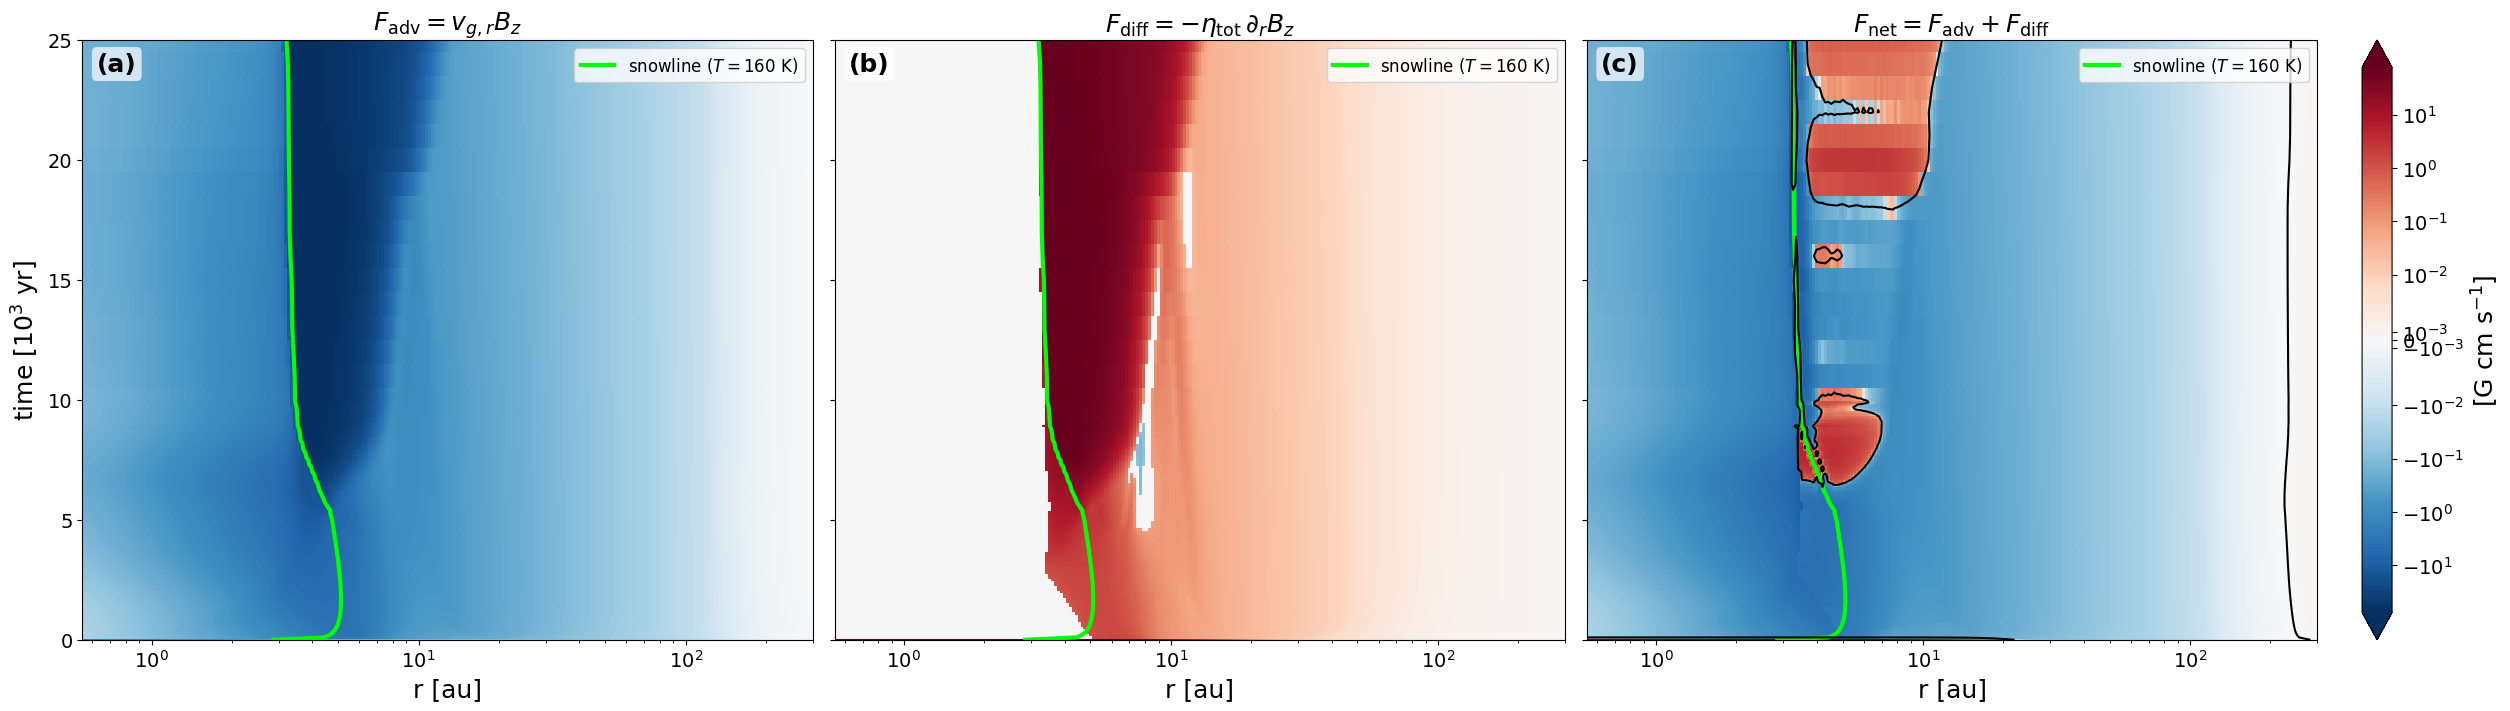

In [8]:
# [旧 cell 59]
# ======================================================
# 磁場の移流フラックス F_adv, 拡散フラックス F_diff と正味のフラックス F_net = F_adv + F_diff の (r,t) 時空図 (1x3 ミニマップ) + スノーライン(T=160K)
# 誘導方程式 dB/dt = -(1/r) d/dr [ r (F_adv + F_diff) ] のフラックス (外向きが正. 2 pi r を掛ける前. 上のセルの 2 pi r F)
#   F_adv  = v_g B ,  F_diff = -eta dB/dr
#   F_net = F_adv + F_diff : 正味のフラックス (2 pi r F_net = -dPhi(<r)/dt).  F_net > 0 なら正味で磁束が外向き, < 0 なら内向き
#   黒線: F_net = 0 (移流と拡散が釣り合い, 正味の輸送の向きが変わる)
# F_adv, F_diff はコード (magnetic_field1D.cpp Calc_Mag) と同じ面上の値 (cell 55 の calc_dBdt と同じ再構成):
#   B_bod, v_bod, eta_bod は sqrt(Sigma_g) 重みの Roe 平均, dB/dr は cff_R_Half の3点 (B[i], B_bod[i], B[i-1])
#   内部面 (r_bod[1..n-1]) のみ描く (境界面は F_diff = 0)
# eta_tot = min(etaO_R + etaA_R, eta_max)   (use_eta_cap = True: コードと同じ. eta_max は input から読む)
# フラックスにはなましをかけない. F_net はそのままの値から計算する
# 出力の B は有効数字7桁 (相対丸め誤差 ~5e-7) なので, eta が大きいと F_diff が丸め誤差で決まってしまう.
#   丸め誤差から見積もった誤差より |F_diff| が小さいセルは F_diff = 0 とする (そのセルは F_net = F_adv)
# file_gas 列: 0:r_cen 1:sigmag 4:vg_r 12:T     file_mag 列: 2:B_z 3:etaO_R 4:etaA_R
# 単位は G cm s^-1, 色は SymLogNorm (赤: 正 = 磁束を外向きに運ぶ (Phi(<r) が減る), 青: 負 = 内向きに運ぶ)
# ======================================================

AU = 1.495979e+13

outdir = BASE_DIR
resultdir = MODEL
t_start = 0
rate_max = None      # カラーバーの範囲 [G cm s^-1]. None なら |F_adv|, |F_diff| の 99 パーセンタイル
rate_lin = None      # |rate| < rate_lin は線形. None なら rate_max * 1e-4
B_round = 1.0e-2     # 出力 B の相対丸め誤差 (%e, 小数6桁)
use_eta_cap = True   # True: eta_tot を eta_max (input) で上限 (コードと同じ), False: 上限なし

path_gas = outdir + resultdir
path_mag = outdir + resultdir + "_B"
years = list_years(path_gas, t_start, path_mag=path_mag)

# eta_max は計算時の input から読む
eta_max = 1.0e20
with open(path_gas + "/input") as f:
    for line in f:
        if line.split("//")[0].split("=")[0].strip() == "eta_max":
            eta_max = float(line.split("//")[0].split("=")[1])

def calc_face_flux(r, sig, vgr, B, eta):
    # 内部面 r_bod[1..n-1] での F_adv, F_diff と F_diff の丸め誤差 (cell 55 の calc_dBdt と同じ再構成)
    q = r[1] / r[0]
    r_bod = r[1:] / np.sqrt(q)                 # log grid: r_cen = sqrt(r_bod[i]*r_bod[i+1])
    w = np.sqrt(sig[1:]) / (np.sqrt(sig[1:]) + np.sqrt(sig[:-1]))
    v_bod = w * vgr[1:] + (1.0 - w) * vgr[:-1]
    B_bod = w * B[1:] + (1.0 - w) * B[:-1]
    eta_bod = w * eta[1:] + (1.0 - w) * eta[:-1]
    s = r_bod - r[:-1]
    t = r[1:] - r_bod
    dBdr = (s*s * B[1:] + (t*t - s*s) * B_bod - t*t * B[:-1]) / (s * t * (s + t))
    dBdr = np.where(B[1:] == B[:-1], 0.0, dBdr)
    F_adv = v_bod * B_bod
    F_diff = -eta_bod * dBdr
    dB = B_round * np.abs(B)
    err_F = eta_bod * (s*s * dB[1:] + np.abs(t*t - s*s) * (w * dB[1:] + (1.0 - w) * dB[:-1])
                       + t*t * dB[:-1]) / (s * t * (s + t))
    return r_bod, F_adv, F_diff, err_F

adv_map, diff_map, r_snow = [], [], []
for year in years:
    gas = np.loadtxt(path_gas + "/out{}_gas".format(year), usecols=(0, 1, 4, 12))
    r, sig, vgr, T = gas.T
    mag = np.loadtxt(path_mag + "/out{}_B".format(year), usecols=(2, 3, 4))
    B, etaO, etaA = mag.T
    eta = np.minimum(etaO + etaA, eta_max) if use_eta_cap else etaO + etaA
    r_bod, F_adv, F_diff, err_F = calc_face_flux(r, sig, vgr, B, eta)

    adv = F_adv
    diff = F_diff
    err = err_F
    adv_map.append(adv)
    diff_map.append(np.where(np.abs(diff) > err, diff, 0.0))

    r_snow.append(find_snowline(r, T))

adv_map = np.array(adv_map)
diff_map = np.array(diff_map)
F_net = adv_map + diff_map

t = np.array(years) / 1.0e3
rb_au = r_bod / AU
if rate_max is None:
    rate_max = np.nanpercentile(np.abs(np.concatenate([adv_map.ravel(), diff_map.ravel()])), 99)
if rate_lin is None:
    rate_lin = rate_max * 1.0e-4
norm_rate = SymLogNorm(linthresh=rate_lin, vmin=-rate_max, vmax=rate_max, base=10)

fig, axes = plt.subplots(1, 3, figsize=(25, 7), sharey=True, layout="constrained")
panels = [(adv_map, norm_rate, r"$F_{\rm adv} = v_{g,r} B_z$"),
          (diff_map, norm_rate, r"$F_{\rm diff} = -\eta_{\rm tot}\, \partial_r B_z$"),
          (F_net, norm_rate, r"$F_{\rm net} = F_{\rm adv} + F_{\rm diff}$")]
pcs = []
for ax, (data, norm, title) in zip(axes, panels):
    ax.set_facecolor("lightgray")
    pcs.append(ax.pcolormesh(rb_au, t, data, cmap="RdBu_r", norm=norm, shading="nearest", rasterized=True))
    ax.plot(r_snow, t, color="lime", lw=3, label=r"snowline ($T = {:.0f}$ K)".format(T_snow))
    ax.set_xscale("log")
    ax.set_xlabel("r [au]", fontsize=18)
    ax.set_xlim((r_min, r_max))
    ax.set_ylim((t[0], t[-1]))
    ax.set_title(title, fontsize=18)
    ax.tick_params(labelsize=14)
    ax.legend(fontsize=12, loc="upper right")
axes[0].set_ylabel(r"time [$10^3$ yr]", fontsize=18)

# F_net = 0 (移流と拡散が釣り合う) の等高線
axes[2].contour(rb_au, t, F_net, levels=[0.0], colors="black", linewidths=1.5)

cb = fig.colorbar(pcs[0], ax=axes, pad=0.02, extend="both")
cb.set_label(r"[G cm s$^{-1}$]", fontsize=18)
cb.ax.tick_params(labelsize=14)
eta_label = r" ($\eta_{{\rm tot}} \leq {:.0e}$ cm$^2$ s$^{{-1}}$)".format(eta_max) if use_eta_cap else r" ($\eta_{\rm tot}$ cap off)"
# fig.suptitle(model_names[resultdir] + " : advective / diffusive flux of $B_z$" + eta_label, fontsize=16)
plt.show()

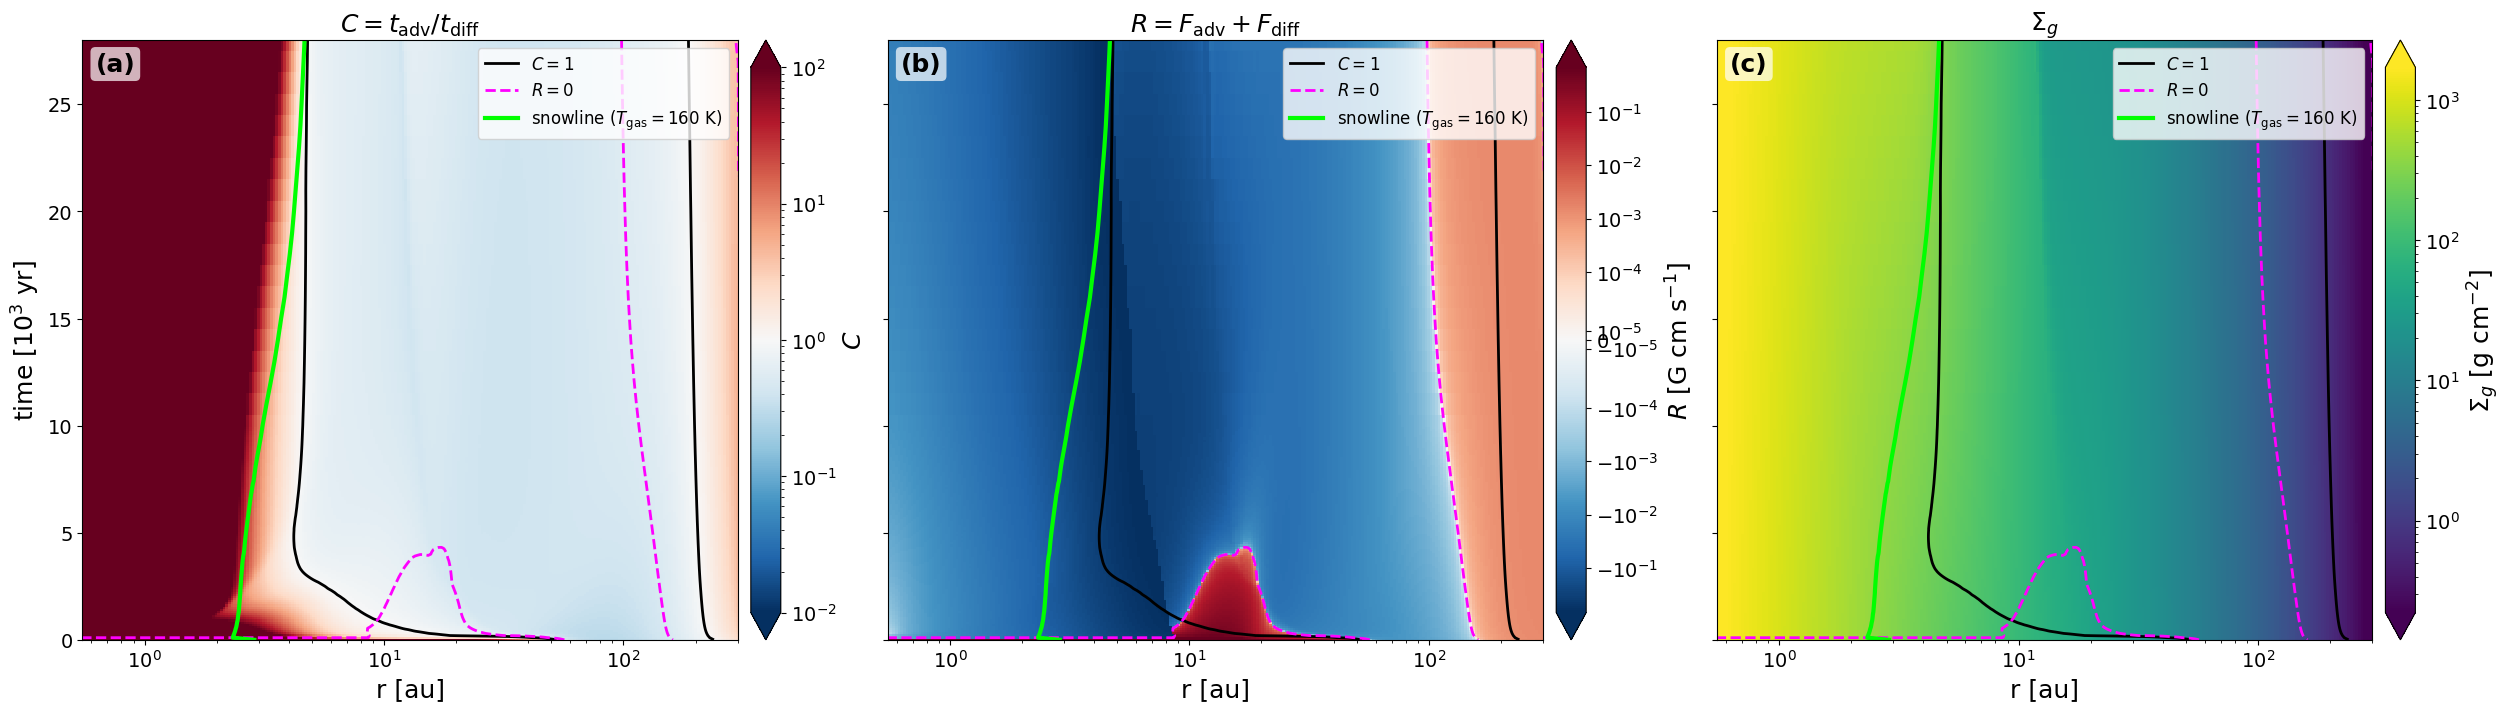

In [16]:
# [旧 cell 60]
# ======================================================
# C = t_adv/t_diff ・ R = F_adv + F_diff (磁場の正味のフラックス) ・ ガス面密度 Sigma_g の (r,t) 時空図 (1x3 ミニマップ) + スノーライン(T=160K)
# 全てのパネルに C = 1 (黒実線) と R = 0 (マゼンタ破線) の等高線を描く
# C = eta_tot/(r |v_g,r|)              (cell 38 と同じ定義: t_adv = r/|v_g,r| , t_diff = r^2/eta_tot)
# R = F_adv + F_diff , F_adv = v_g B_z , F_diff = -eta_tot dB_z/dr   (外向きが正. cell 58 の F_net と同じ. 2 pi r R = -dPhi(<r)/dt)
#   R > 0 : 正味で磁束が外向き, R < 0 : 内向き.  R = 0 で移流と拡散が釣り合う
#   F_adv, F_diff はコード (magnetic_field1D.cpp Calc_Mag) と同じ面上の値 (cell 55 の calc_dBdt と同じ再構成):
#   B_bod, v_bod, eta_bod は sqrt(Sigma_g) 重みの Roe 平均, dB/dr は cff_R_Half の3点. 内部面 r_bod[1..n-1] のみ
# eta_tot = min(etaO_R + etaA_R, eta_max)   (use_eta_cap = True: コードと同じ. eta_max は input から読む)
# v_g,r と F_adv, F_diff にはなましをかけない. C と R はそのままの値から計算する
#   (cell 38 の C も同じくなましなし)
# 出力の B は有効数字7桁 (相対丸め誤差 ~5e-7) なので, 丸め誤差から見積もった誤差より |F_diff| が小さいセルは
#   F_diff = 0 とする (そのセルは R = F_adv)
# file_gas 列: 0:r_cen 1:sigmag 4:vg_r 12:T     file_mag 列: 2:B_z 3:etaO_R 4:etaA_R
# ======================================================

AU = 1.495979e+13

outdir = BASE_DIR
resultdir = MODEL
t_start = 0
C_range = (1.0e-2, 1.0e2)      # C のカラーバーの範囲
R_max = None         # R のカラーバーの範囲 [G cm s^-1]. None なら |R| の 99 パーセンタイル
R_lin = None         # |R| < R_lin は線形. None なら R_max * 1e-4
sig_range = None     # Sigma_g のカラーバーの範囲 [g cm^-2]. None なら 1-99 パーセンタイル
B_round = 1.0e-2     # 出力 B の相対丸め誤差 (%e, 小数6桁)
use_eta_cap = True   # True: eta_tot を eta_max (input) で上限 (コードと同じ), False: 上限なし

path_gas = outdir + resultdir
path_mag = outdir + resultdir + "_B"
years = list_years(path_gas, t_start, path_mag=path_mag)

# eta_max は計算時の input から読む
eta_max = 1.0e20
with open(path_gas + "/input") as f:
    for line in f:
        if line.split("//")[0].split("=")[0].strip() == "eta_max":
            eta_max = float(line.split("//")[0].split("=")[1])

def calc_face_flux(r, sig, vgr, B, eta):
    # 内部面 r_bod[1..n-1] での F_adv, F_diff と F_diff の丸め誤差 (cell 58 と同じ)
    q = r[1] / r[0]
    r_bod = r[1:] / np.sqrt(q)                 # log grid: r_cen = sqrt(r_bod[i]*r_bod[i+1])
    w = np.sqrt(sig[1:]) / (np.sqrt(sig[1:]) + np.sqrt(sig[:-1]))
    v_bod = w * vgr[1:] + (1.0 - w) * vgr[:-1]
    B_bod = w * B[1:] + (1.0 - w) * B[:-1]
    eta_bod = w * eta[1:] + (1.0 - w) * eta[:-1]
    s = r_bod - r[:-1]
    t = r[1:] - r_bod
    dBdr = (s*s * B[1:] + (t*t - s*s) * B_bod - t*t * B[:-1]) / (s * t * (s + t))
    dBdr = np.where(B[1:] == B[:-1], 0.0, dBdr)
    F_adv = v_bod * B_bod
    F_diff = -eta_bod * dBdr
    dB = B_round * np.abs(B)
    err_F = eta_bod * (s*s * dB[1:] + np.abs(t*t - s*s) * (w * dB[1:] + (1.0 - w) * dB[:-1])
                       + t*t * dB[:-1]) / (s * t * (s + t))
    return r_bod, F_adv, F_diff, err_F

C_map, R_map, sig_map, r_snow = [], [], [], []
for year in years:
    gas = np.loadtxt(path_gas + "/out{}_gas".format(year), usecols=(0, 1, 4, 12))
    r, sig, vgr, Tgas = gas.T
    mag = np.loadtxt(path_mag + "/out{}_B".format(year), usecols=(2, 3, 4))
    B, etaO, etaA = mag.T
    eta = np.minimum(etaO + etaA, eta_max) if use_eta_cap else etaO + etaA

    # R: 面上のフラックス (cell 58 と同じ)
    r_bod, F_adv, F_diff, err_F = calc_face_flux(r, sig, vgr, B, eta)
    F_adv = F_adv
    F_diff = F_diff
    err_F = err_F
    F_diff = np.where(np.abs(F_diff) > err_F, F_diff, 0.0)
    R_map.append(F_adv + F_diff)

    # C: セル中心 (v_g,r)
    vgr = vgr
    with np.errstate(divide="ignore", invalid="ignore"):
        C = eta / (r * np.abs(vgr))
    C_map.append(np.where(np.isfinite(C) & (C > 0.0), C, np.nan))
    sig_map.append(sig)

    # スノーライン: T が T_snow を横切る最も外側の半径 (log r で線形補間)
    k = np.where((Tgas[:-1] - T_snow) * (Tgas[1:] - T_snow) <= 0.0)[0]
    if len(k) == 0:
        r_snow.append(np.nan)
    else:
        k = k[-1]
        x = (T_snow - Tgas[k]) / (Tgas[k + 1] - Tgas[k])
        r_snow.append(10.0**(np.log10(r[k]) + x * (np.log10(r[k + 1]) - np.log10(r[k]))) / AU)

C_map = np.array(C_map)
R_map = np.array(R_map)
sig_map = np.array(sig_map)
t = np.array(years) / 1.0e3
r_au = r / AU
rb_au = r_bod / AU
sel = (r_au >= r_min) & (r_au <= r_max)
if sig_range is None:
    sig_range = tuple(np.nanpercentile(sig_map[:, sel][sig_map[:, sel] > 0.0], [1, 99]))
if R_max is None:
    R_max = np.nanpercentile(np.abs(R_map), 99)
if R_lin is None:
    R_lin = R_max * 1.0e-4

# C = 1 の等高線用 (log10 で 0 を等高線にする). R = 0 は R をそのまま線形補間 (R は面 rb_au 上)
with np.errstate(divide="ignore", invalid="ignore"):
    logC = np.ma.masked_invalid(np.log10(C_map))

fig, axes = plt.subplots(1, 3, figsize=(25, 7), sharey=True, layout="constrained")
panels = [(r_au, C_map, LogNorm(vmin=C_range[0], vmax=C_range[1]), "RdBu_r",
           r"$C = t_{\rm adv}/t_{\rm diff}$", r"$C$"),
          (rb_au, R_map, SymLogNorm(linthresh=R_lin, vmin=-R_max, vmax=R_max, base=10), "RdBu_r",
           r"$R = F_{\rm adv} + F_{\rm diff}$", r"$R$ [G cm s$^{-1}$]"),
          (r_au, sig_map, LogNorm(vmin=sig_range[0], vmax=sig_range[1]), "viridis",
           r"$\Sigma_g$", r"$\Sigma_g$ [g cm$^{-2}$]")]
for ax, (x, data, norm, cmap, title, cb_label) in zip(axes, panels):
    ax.set_facecolor("lightgray")
    pc = ax.pcolormesh(x, t, data, cmap=cmap, norm=norm, shading="nearest", rasterized=True)
    ax.contour(r_au, t, logC, levels=[0.0], colors="black", linewidths=2.0, linestyles="solid")
    ax.contour(rb_au, t, R_map, levels=[0.0], colors="magenta", linewidths=2.0, linestyles="dashed")
    ax.plot(r_snow, t, color="lime", lw=3)
    ax.set_xscale("log")
    ax.set_xlabel("r [au]", fontsize=18)
    ax.set_xlim((r_min, r_max))
    ax.set_ylim((t[0], t[-1]))
    ax.set_title(title, fontsize=18)
    ax.tick_params(labelsize=14)
    cb = fig.colorbar(pc, ax=ax, pad=0.02, extend="both")
    cb.set_label(cb_label, fontsize=18)
    cb.ax.tick_params(labelsize=14)
axes[0].set_ylabel(r"time [$10^3$ yr]", fontsize=18)
handles = [Line2D([], [], color="black", lw=2.0, ls="solid", label=r"$C = 1$"),
           Line2D([], [], color="magenta", lw=2.0, ls="dashed", label=r"$R = 0$"),
           Line2D([], [], color="lime", lw=3, label=r"snowline ($T_{{\rm gas}} = {:.0f}$ K)".format(T_snow))]
for ax in axes:
    ax.legend(handles=handles, fontsize=12, loc="upper right")
eta_label = r" ($\eta_{{\rm tot}} \leq {:.0e}$ cm$^2$ s$^{{-1}}$)".format(eta_max) if use_eta_cap else r" ($\eta_{\rm tot}$ cap off)"
# fig.suptitle(model_names[resultdir] + eta_label, fontsize=16)
plt.show()

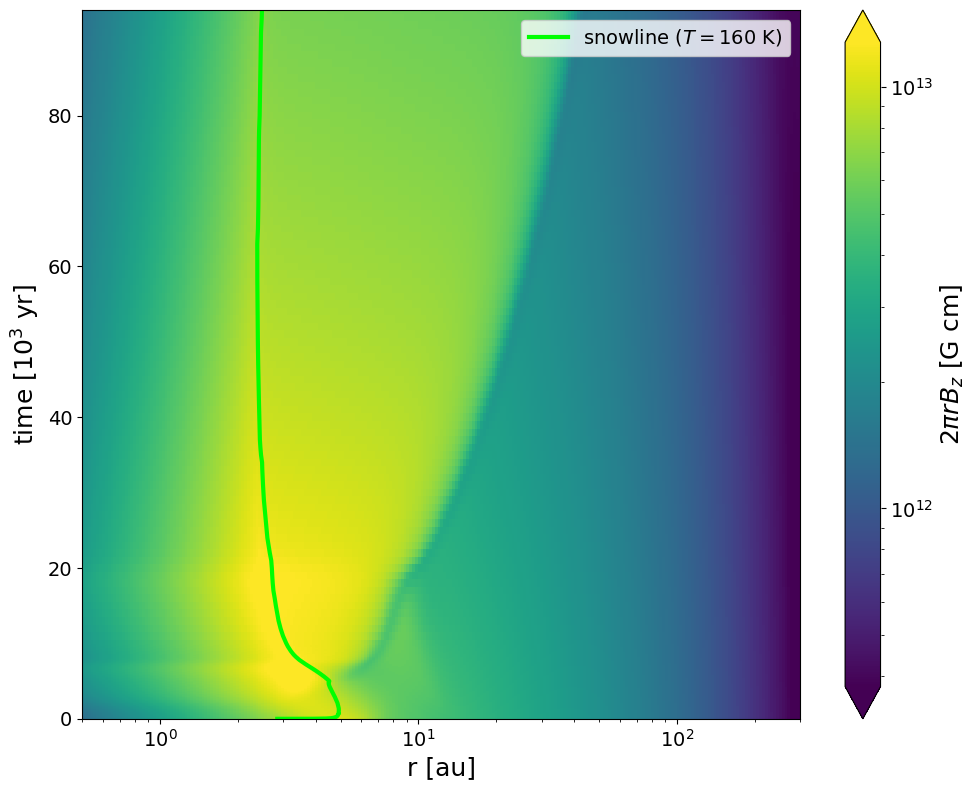

In [14]:
# [旧 cell 66]
# ======================================================
# 円環での磁束 2 pi r B_z (= dPhi/dr, Phi(<r) = int 2 pi r B_z dr の被積分関数) の (r,t) 時空図 + スノーライン(T=160K)
# 単位は G cm, 色は LogNorm (B_z <= 0 のセルは灰色)
# file_gas 列: 0:r_cen 12:T     file_mag 列: 2:B_z
# ======================================================

AU = 1.495979e+13

outdir = BASE_DIR
resultdir = MODEL
t_start = 0
flux_range = None    # カラーバーの範囲 [G cm]. None なら r_min < r < r_max での 1-99 パーセンタイル

path_gas = outdir + resultdir
path_mag = outdir + resultdir + "_B"
years = list_years(path_gas, t_start, path_mag=path_mag)

flux_rt, r_snow = [], []
for year in years:
    gas = np.loadtxt(path_gas + "/out{}_gas".format(year), usecols=(0, 12))
    r, T = gas[:, 0], gas[:, 1]
    B = np.loadtxt(path_mag + "/out{}_B".format(year), usecols=(2,))
    flux_rt.append(2.0 * np.pi * r * B)

    r_snow.append(find_snowline(r, T))

flux_rt = np.array(flux_rt)
t = np.array(years) / 1.0e3
r_au = r / AU
sel = (r_au >= r_min) & (r_au <= r_max)
if flux_range is None:
    v = flux_rt[:, sel]
    flux_range = tuple(np.nanpercentile(v[v > 0.0], [1, 99]))

fig, ax = plt.subplots(figsize=(10, 8))
ax.set_facecolor("lightgray")
pc = ax.pcolormesh(r_au, t, flux_rt, cmap="viridis", norm=LogNorm(vmin=flux_range[0], vmax=flux_range[1]),
                   shading="nearest", rasterized=True)
cb = fig.colorbar(pc, ax=ax, extend="both")
cb.set_label(r"$2\pi r B_z$ [G cm]", fontsize=18)
cb.ax.tick_params(labelsize=14)

ax.plot(r_snow, t, color="lime", lw=3, label=r"snowline ($T = {:.0f}$ K)".format(T_snow))

ax.set_xscale("log")
ax.set_xlabel("r [au]", fontsize=18)
ax.set_ylabel(r"time [$10^3$ yr]", fontsize=18)
ax.set_xlim((r_min, r_max))
ax.set_ylim((t[0], t[-1]))
ax.tick_params(labelsize=14)
ax.legend(fontsize=14, loc="upper right")
plt.tight_layout()
os.makedirs(FIG_DIR, exist_ok=True)
# plt.savefig(fig_path("flux_rt.png", root=ANALYSIS_FIG_DIR))
plt.show()

## 質量の時間進化

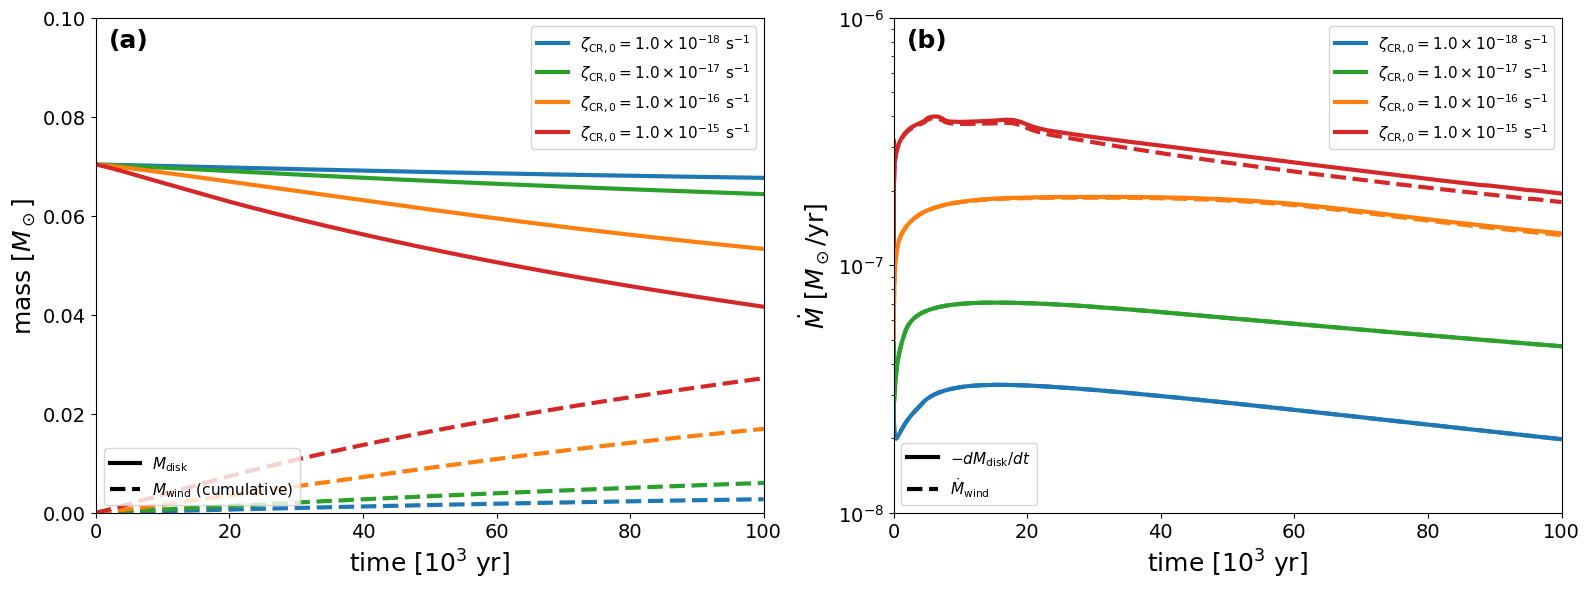

In [17]:
# [旧 cell 36]
# ======================================================
# 計算領域内の円盤(ガス)質量 と wind による累積質量損失 の時間進化
# file_gas 列: 0:r_cen 1:sigmag 4:vg_r 11:dsigmagdt_w [g/cm^2/s]
# M_disk = sum_i Sigma_g,i * pi*(r_bod,i+1^2 - r_bod,i^2)   (計算領域内のみ)
# M_wind(t) = int_0^t dt' sum_i dSigma_w/dt,i * pi*(r_bod,i+1^2 - r_bod,i^2)  (出力間隔で台形積分)
# -dM_disk/dt = Mdot_in + Mdot_out + Mdot_wind  (各出力時刻の境界フラックス; CalcGasFlux と同じ扱い)
#   Mdot_in  = -2*pi*r_bod,in *Sigma_0  *vr_0   (vr_0 < 0 のときのみ: 中心星への流出)
#   Mdot_out =  2*pi*r_bod,out*Sigma_N-1*vr_N-1 (vr_N-1 > 0 のときのみ: 外側からの流入はなし)
# ======================================================

Msolar = 1.989000e+33
yr = 3.155760e+07

outdir = BASE_DIR
resultdirs = ["/beta4_zeta1e18", "/beta4","/beta4_zeta1e16","/beta4_zeta1e15"]
colors = ["tab:blue", "tab:green","tab:orange", "tab:red"]
# ディレクトリ名 -> 図に表示するモデル名
zeta_labels = {
    # "beta4_zeta1e18": r"$\zeta_\mathrm{CR,0} = 1.0 \times 10^{-18}\ \rm{s^{-1}}$",
    "/beta4_zeta1e18":          r"$\zeta_\mathrm{CR,0} = 1.0 \times 10^{-18}\ \rm{s^{-1}}$",
    "/beta4": r"$\zeta_\mathrm{CR,0} = 1.0 \times 10^{-17}\ \rm{s^{-1}}$",
    "/beta4_zeta1e16": r"$\zeta_\mathrm{CR,0} = 1.0 \times 10^{-16}\ \rm{s^{-1}}$",
    "/beta4_zeta1e15": r"$\zeta_\mathrm{CR,0} = 1.0 \times 10^{-15}\ \rm{s^{-1}}$",
}

def cell_boundary(r_cen):
    # log grid: r_cen = sqrt(r_bod[i]*r_bod[i+1]) -> r_bod = r_cen/sqrt(q)
    q = r_cen[1] / r_cen[0]
    return np.append(r_cen / np.sqrt(q), r_cen[-1] * np.sqrt(q))

def cell_area(r_cen):
    r_bod = cell_boundary(r_cen)
    return np.pi * (r_bod[1:]**2 - r_bod[:-1]**2)

def mass_history(path):
    years = list_years(path)
    t, M_gas, Mdot_w, Mdot_in, Mdot_out = [], [], [], [], []
    for year in years:
        data = np.loadtxt(path + "/out{}_gas".format(year), usecols=(0, 1, 4, 11))
        r_bod = cell_boundary(data[:, 0])
        area = np.pi * (r_bod[1:]**2 - r_bod[:-1]**2)
        sig, vr = data[:, 1], data[:, 2]
        t.append(year)
        M_gas.append(np.sum(sig * area))
        Mdot_w.append(np.sum(data[:, 3] * area))
        Mdot_in.append(-2.0 * np.pi * r_bod[0] * sig[0] * vr[0] if vr[0] < 0.0 else 0.0)
        Mdot_out.append(2.0 * np.pi * r_bod[-1] * sig[-1] * vr[-1] if vr[-1] > 0.0 else 0.0)
    t = np.array(t, dtype=float)
    Mdot_w = np.array(Mdot_w)
    Mdot_tot = Mdot_w + np.array(Mdot_in) + np.array(Mdot_out)   # = -dM_disk/dt
    M_wind = np.concatenate(([0.0], np.cumsum(0.5 * (Mdot_w[1:] + Mdot_w[:-1]) * np.diff(t) * yr)))
    return t, np.array(M_gas) / Msolar, M_wind / Msolar, Mdot_w / Msolar * yr, Mdot_tot / Msolar * yr

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for rd, c in zip(resultdirs, colors):
    t, M_gas, M_wind, Mdot_w, Mdot_tot = mass_history(outdir + rd)
    axes[0].plot(t / 1.0e3, M_gas, color=c, lw=3)
    axes[0].plot(t / 1.0e3, M_wind, color=c, lw=3, linestyle="dashed")
    axes[1].plot(t / 1.0e3, Mdot_tot, color=c, lw=3)
    axes[1].plot(t / 1.0e3, Mdot_w, color=c, lw=3, linestyle="dashed")

axes[0].set_xlabel(r"time [$10^3$ yr]", fontsize=18)
axes[0].set_ylabel(r"mass [$M_\odot$]", fontsize=18)
# axes[0].set_title("gas mass in computational domain / mass lost by wind", fontsize=14)
model_handles = [Line2D([], [], color=c, lw=3, label=zeta_labels[d]) for d, c in zip(resultdirs, colors)]
line_handles = [Line2D([], [], color="black", lw=3, label=r"$M_{\rm disk}$"),
                Line2D([], [], color="black", lw=3, linestyle="dashed", label=r"$M_{\rm wind}$ (cumulative)")]
leg_model = axes[0].legend(handles=model_handles, fontsize=11, loc="upper right")
axes[0].add_artist(leg_model)
axes[0].legend(handles=line_handles, fontsize=11, loc="lower left")

axes[1].set_xlabel(r"time [$10^3$ yr]", fontsize=18)
axes[1].set_ylabel(r"$\dot{M}$ [$M_\odot$/yr]", fontsize=18)
axes[1].set_yscale("log")
rate_handles = [Line2D([], [], color="black", lw=3, label=r"$-dM_{\rm disk}/dt$"),
                Line2D([], [], color="black", lw=3, linestyle="dashed", label=r"$\dot{M}_{\rm wind}$")]
leg_model1 = axes[1].legend(handles=model_handles, fontsize=11, loc="upper right")
axes[1].add_artist(leg_model1)
axes[1].legend(handles=rate_handles, fontsize=11, loc="lower left")

axes[0].set_ylim(0, 1.0e-1)
axes[1].set_ylim(1.0e-8, 1.0e-6)

for ax in axes:
    ax.set_xlim(t_min, t_max)
    ax.tick_params(labelsize=14)
plt.tight_layout()
plt.savefig(fig_path("dMdt.png", resultdirs, root=ANALYSIS_FIG_DIR))
plt.show()

## リング・ギャップを重ねた図 (時刻固定の cell 51 を含む)

In [16]:
# ギャップ検出 (thesis_common.ipynb の MODEL に対して計算する)
run_nb("gap_detection.ipynb")

In [18]:
# [旧 cell 50]
# ======================================================
# dSigma_g/dt と dSigma_d,tot/dt の (r,t) 時空図 (1x2 ミニマップ) + r_ring, r_gap
# どちらもコードの更新式と同じフラックス形式で, 各出力時刻の瞬間値を計算する
# dSigma_g/dt     : cell 46 の calc_dSdt
# dSigma_d,tot/dt : calc_dSddt (下で定義, 蒸気を含む全ダスト). 合体・破砕と昇華・凝結は Sigma_d,tot を保存するので入らない
#   = sum_j [ -div(F_adv,j) - div(F_diff,j) - (dSigma_d,j/dt)_wind ] - div(F_adv,vap) - div(F_diff,vap) - (dSigma_vap/dt)_wind
#   div(F) = 2 (r_bod[i+1] F[i+1] - r_bod[i] F[i]) / (r_bod[i+1]^2 - r_bod[i]^2)
#   F_adv,j  : CalcDustFlux と同じ風上フラックス (面速度は sqrt(Sigma_d,j) 重みの Roe 平均, 境界は流出のみ,
#              両側とも Sigma_d,j < floor の面は 0). v_d,r,j は CalcDustVelocity_TM2018 の式
#              (M_in, v_K, A は Sigma_g から再構成, dv_g,phi = v_g,phi - v_K)
#   F_adv,vap: 速度 v_g,r, Roe 重みは sqrt(Sigma_vap/Sigma_g)
#   F_diff   : ApplyDustDiffusionImplicit の面フラックス -D_face Sigma_g,face (f_i - f_{i-1})/(r_i - r_{i-1}) , f = Sigma/Sigma_g
#              D = alpha_MRI c_s H_g/(1+St^2) (ダスト), alpha_tot c_s H_g (蒸気). 境界面は 0
#   wind     : CalcWindMassLoss_Tabone2022 (Sigma_d,j (dsigmagdt_w/Sigma_g), St > 1e-4 のビンは 0)
# file 列: out (1行目: m_j, 3行目: a_j, 5行目以降: 0:r_cen 1~:Sigma_d,j)
#          out_gas 0:r_cen 1:sigmag 3:sigmad_vapor 4:vg_r 5:vg_phi 6:vg_wind 11:dsigmagdt_w 12:T 18:alpha_tot   out_B 1:alpha_MRI
# 単位は g cm^-2 yr^-1, 色は SymLogNorm (赤: 増加, 青: 減少)
# ======================================================

AU = 1.495979e+13
yr = 3.155760e+07
G = 6.67408e-08
kB = 1.38064852e-16
mg = 2.34 * 1.672621898e-24   # GAS_MOLECULAR_MASS
Msolar = 1.989000e+33
sigma_h2 = 2.0e-15

outdir = BASE_DIR
resultdir = MODEL
M_star = 1.0 * Msolar
rho_int = 1.4                 # ダストの内部密度 [g cm^-3] (input の rhodi)
t_start = 0
rate_max_g, rate_lin_g = 1.0e-2, 1.0e-6   # ガスのカラーバー範囲 [g cm^-2 yr^-1]
rate_max_d, rate_lin_d = 1.0e-4, 1.0e-8   # ダストのカラーバー範囲 [g cm^-2 yr^-1]

path_gas = outdir + resultdir
path_mag = outdir + resultdir + "_B"
years = list_years(path_gas, path_mag=path_mag)

def div_flux(r_bod, F):
    # 2 (r_bod[i+1] F[i+1] - r_bod[i] F[i]) / (r_bod[i+1]^2 - r_bod[i]^2)   (F: (n+1,) or (n+1, nbin))
    w = (r_bod if F.ndim == 1 else r_bod[:, None]) * F
    vol = r_bod[1:]**2 - r_bod[:-1]**2
    return 2.0 * (w[1:] - w[:-1]) / (vol if F.ndim == 1 else vol[:, None])

def upwind_flux(sig, weight, v, skip):
    # 面速度 = sqrt(weight) 重みの Roe 平均, 風上. 境界は流出のみ. skip の面は 0
    n = len(sig)
    s = np.sqrt(np.maximum(weight, 0.0))
    st = s[1:] + s[:-1]
    w = s[1:] / np.where(st > 0.0, st, 1.0)
    u = w * v[1:] + (1.0 - w) * v[:-1]
    F = np.zeros((n + 1,) + sig.shape[1:])
    F[1:n] = np.where(st > 0.0, np.where(u >= 0.0, u * sig[:-1], u * sig[1:]), 0.0)
    F[0] = np.where((s[0] > 0.0) & (v[0] < 0.0), v[0] * sig[0], 0.0)
    F[n] = np.where((s[-1] > 0.0) & (v[-1] > 0.0), v[-1] * sig[-1], 0.0)
    return np.where(skip, 0.0, F)

def calc_dSddt(year):
    # dSigma_d,tot/dt [g cm^-2 s^-1] (蒸気を含む)
    f = path_gas + "/out{}".format(year)
    m_bin = np.array([float(x) for x in linecache.getline(f, 1).split()])
    a_bin = np.array([float(x) for x in linecache.getline(f, 3).split()])
    linecache.clearcache()
    sigd = np.loadtxt(f, skiprows=5)[:, 1:]
    gas = np.loadtxt(path_gas + "/out{}_gas".format(year), usecols=(0, 1, 3, 4, 5, 6, 11, 12, 18))
    r, sigmag, sigv, vgr, vgphi, vgw, dsgw, T, alpha_tot = gas.T
    alpha = np.loadtxt(path_mag + "/out{}_B".format(year), usecols=(1,))

    # 格子と円盤量 (log 格子: r_cen = sqrt(r_bod[i] r_bod[i+1]))
    n = len(r)
    q = r[1] / r[0]
    r_bod = np.append(r / np.sqrt(q), r[-1] * np.sqrt(q))
    vol = r_bod[1:]**2 - r_bod[:-1]**2
    dM = np.pi * sigmag * vol
    dM[0] = np.pi * sigmag[0] * r_bod[1]**2
    M_in = M_star + np.cumsum(dM)
    Omega = np.sqrt(G * M_in / r**3)
    A = (2.0 * np.pi * r**2 * sigmag / M_in)[:, None]
    dvphi = (vgphi - r * Omega)[:, None]
    cs = np.sqrt(kB * T / mg)
    Hg = cs / Omega
    mfp = (1.0 / (sigmag / (np.sqrt(2.0 * np.pi) * Hg) / mg * sigma_h2))[:, None]
    sg = sigmag[:, None]
    St = np.where(a_bin < 2.25 * mfp, 0.5 * np.pi * rho_int * a_bin / sg,
                  2.0 * np.pi * rho_int * a_bin**2 / (9.0 * mfp * sg))
    above = sigd > np.maximum(1.0e-50, m_bin / (np.pi * vol)[:, None])

    # 移流 (ダスト各ビン, 蒸気)
    vdr = ((1.0 + A * St**2) * vgr[:, None] + 2.0 * St * dvphi - St**2 * vgw[:, None]) / (1.0 + (1.0 + A) * St**2)
    vdr = np.where(above, vdr, 0.0)
    skip = np.zeros((n + 1, len(a_bin)), dtype=bool)
    skip[1:n] = ~above[1:] & ~above[:-1]
    F_adv = upwind_flux(sigd, sigd, vdr, skip)
    vv = np.where(sigv > np.maximum(1.0e-50, m_bin[0] / (np.pi * vol)), vgr, 0.0)
    F_vap = upwind_flux(sigv, sigv / sigmag, vv, np.zeros(n + 1, dtype=bool))

    # 乱流拡散 (境界面は 0)
    dr = r[1:] - r[:-1]
    sgf = 0.5 * (sigmag[1:] + sigmag[:-1])
    Dd = (alpha * cs * Hg)[:, None] / (1.0 + St**2)
    thr = np.maximum(1.0e-20 * sigd.sum(axis=1), 1.0e-20)[:, None]
    gate = (sigd[1:] > thr[1:]) & (sigd[:-1] > thr[:-1])
    F_dif = np.zeros((n + 1, len(a_bin)))
    F_dif[1:n] = np.where(gate, -0.5 * (Dd[1:] + Dd[:-1]) * (sgf / dr)[:, None] * (sigd[1:] / sg[1:] - sigd[:-1] / sg[:-1]), 0.0)
    nu = alpha_tot * cs * Hg
    F_vdif = np.zeros(n + 1)
    F_vdif[1:n] = np.where((sigv[1:] > 1.0e-20) & (sigv[:-1] > 1.0e-20),
                           -0.5 * (nu[1:] + nu[:-1]) * sgf / dr * (sigv[1:] / sigmag[1:] - sigv[:-1] / sigmag[:-1]), 0.0)

    # 風による除去
    Aw = np.where(sigmag > 1.0e-4, dsgw / sigmag, 0.0)
    w_d = np.where(above & (St <= 1.0e-4), sigd, 0.0).sum(axis=1) * Aw
    w_v = np.where(sigv > 1.0e-50, sigv, 0.0) * Aw

    return (-div_flux(r_bod, F_adv + F_dif).sum(axis=1) - div_flux(r_bod, F_vap + F_vdif) - w_d - w_v)

dSgdt, dSddt = [], []
for year in years:
    gas = np.loadtxt(path_gas + "/out{}_gas".format(year), usecols=(0, 1, 4, 11))
    r, sig, vgr, dsdt_w = gas.T
    dSgdt.append(calc_dSdt(r, sig, vgr, dsdt_w) * yr)
    dSddt.append(calc_dSddt(year) * yr)

t_yr = np.array(years, dtype=float)
dSgdt = np.array(dSgdt)
dSddt = np.array(dSddt)

sel = t_yr >= t_start
t = t_yr[sel] / 1.0e3
r_au = r / AU
panels = [(dSgdt[sel], SymLogNorm(linthresh=rate_lin_g, vmin=-rate_max_g, vmax=rate_max_g, base=10),
           r"$\partial \Sigma_{\rm g}/\partial t$"),
          (dSddt[sel], SymLogNorm(linthresh=rate_lin_d, vmin=-rate_max_d, vmax=rate_max_d, base=10),
           r"$\partial \Sigma_{\rm d,tot}/\partial t$")]

t_ring_k, t_gap_k = np.array(t_ring) / 1.0e3, np.array(t_gap) / 1.0e3
m_ring, m_gap = t_ring_k >= t_start / 1.0e3, t_gap_k >= t_start / 1.0e3

fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True)
for ax, (data, norm, title) in zip(axes, panels):
    pc = ax.pcolormesh(r_au, t, data, cmap="RdBu_r", norm=norm, shading="nearest", rasterized=True)
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.set_label(r"[g cm$^{-2}$ yr$^{-1}$]", fontsize=18)
    cb.ax.tick_params(labelsize=14)
    ax.scatter(np.array(r_ring_t)[m_ring] / AU, t_ring_k[m_ring], s=10, color="lime", label=r"$r_{\rm ring}$")
    ax.scatter(np.array(r_gap_t)[m_gap] / AU, t_gap_k[m_gap], s=14, marker="x", color="black", label=r"$r_{\rm gap}$")
    ax.set_xscale("log")
    ax.set_xlim((r_min, r_max))
    ax.set_ylim((t_min, t_max))
    ax.set_xlabel("r [au]", fontsize=18)
    ax.set_title(title, fontsize=18)
    ax.tick_params(labelsize=14)
    ax.legend(fontsize=12, loc="upper right")
axes[0].set_ylabel(r"time [$10^3$ yr]", fontsize=18)
fig.suptitle(model_names[resultdir], fontsize=16)
plt.tight_layout()
plt.show()

NameError: name 'calc_dSdt' is not defined

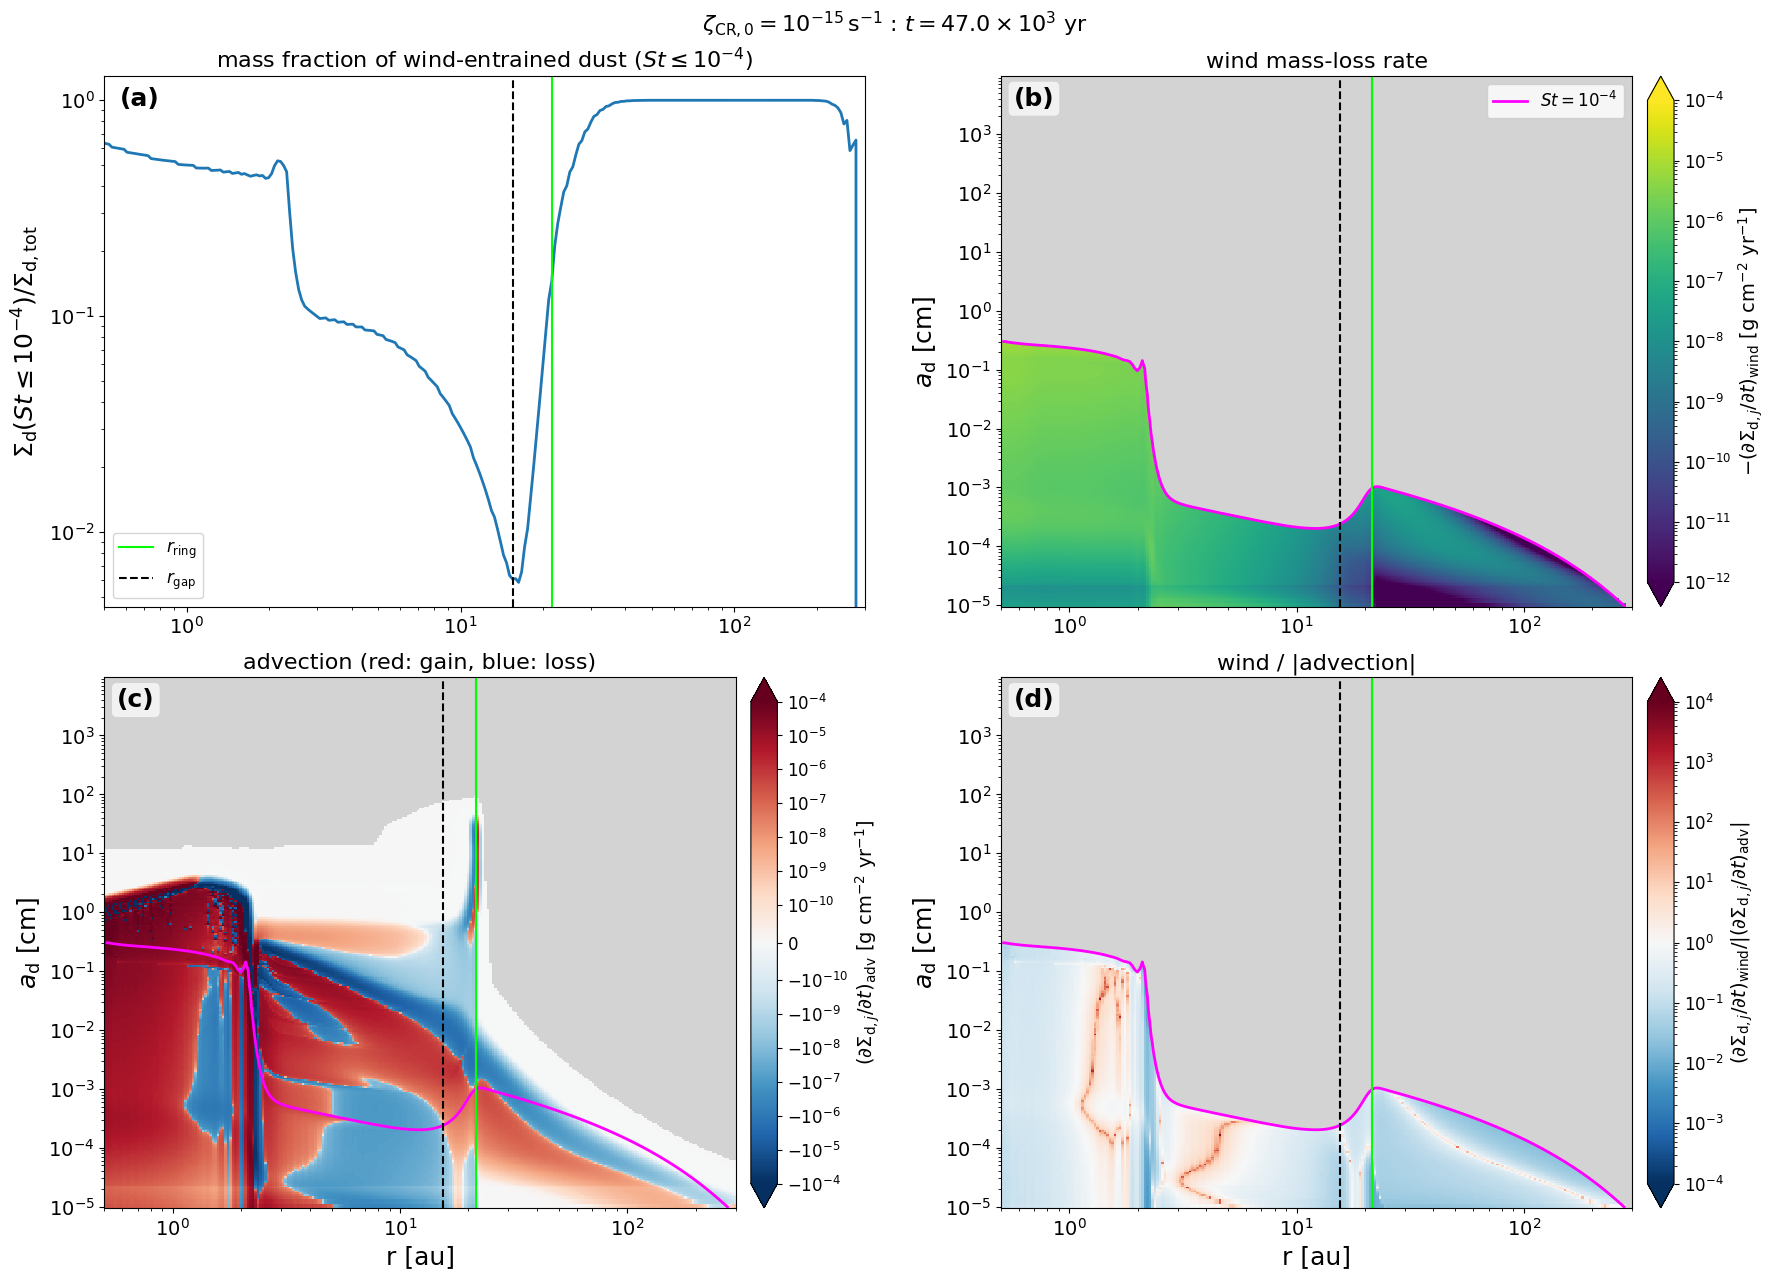

r_ring [au] = [21.53]  r_gap [au] = [15.49]


In [18]:
# [旧 cell 51]
# ======================================================
# ギャップでパイルアップが弱まるかの検証: 時刻 t_fix を固定した (r, a) 分布 (2x2 ミニマップ) + r_ring, r_gap
#   (左上) f_wind = sum_{St<=St_w} Sigma_d,j / sum_j Sigma_d,j  : wind で飛ばされうるダストの質量割合
#   (右上) (dSigma_d,j/dt)_wind = Sigma_d,j (dsigmagdt_w/Sigma_g) , St > St_w と floor 未満のビンは 0
#          (CalcWindMassLoss_Tabone2022 と同じ) -> 損失率として正で描く
#   (左下) (dSigma_d,j/dt)_adv = -div(F_adv,j) : CalcDustFlux と同じ風上フラックス (上のセル calc_dSddt と同じ再構成)
#   (右下) (dSigma_d,j/dt)_wind / |(dSigma_d,j/dt)_adv|
# 上のセルの div_flux, upwind_flux, path_gas, path_mag, M_star, rho_int, sigma_h2 と
# 強度プロファイルのセルの t_ring, r_ring_t, t_gap, r_gap_t を使う (resultdir を揃えること)
# 単位は g cm^-2 yr^-1 (Sigma_d,j はファイルの値 = dSigma_d/dln a)
# ======================================================

t_fix = 47000                          # 固定する時刻 [yr]
St_w = 1.0e-4                          # これ以下の St のダストが wind で飛ぶ (コードと同じ)
wind_range = (1.0e-12, 1.0e-4)         # (dSigma_d/dt)_wind のカラーバー範囲 [g cm^-2 yr^-1]
adv_max, adv_lin = 1.0e-4, 1.0e-10     # (dSigma_d/dt)_adv のカラーバー範囲, 線形領域 [g cm^-2 yr^-1]
ratio_range = 1.0e4                    # 比のカラーバー範囲 [1/ratio_range, ratio_range]

def calc_dust_rates(year):
    # ビンごとの (dSigma_d,j/dt)_adv, (dSigma_d,j/dt)_wind [g cm^-2 s^-1] と St, Sigma_d,j を返す (calc_dSddt と同じ再構成)
    f = path_gas + "/out{}".format(year)
    m_bin = np.array([float(x) for x in linecache.getline(f, 1).split()])
    a_bin = np.array([float(x) for x in linecache.getline(f, 3).split()])
    linecache.clearcache()
    sigd = np.loadtxt(f, skiprows=5)[:, 1:]
    gas = np.loadtxt(path_gas + "/out{}_gas".format(year), usecols=(0, 1, 4, 5, 6, 11, 12))
    r, sigmag, vgr, vgphi, vgw, dsgw, T = gas.T

    n = len(r)
    q = r[1] / r[0]
    r_bod = np.append(r / np.sqrt(q), r[-1] * np.sqrt(q))
    vol = r_bod[1:]**2 - r_bod[:-1]**2
    dM = np.pi * sigmag * vol
    dM[0] = np.pi * sigmag[0] * r_bod[1]**2
    M_in = M_star + np.cumsum(dM)
    Omega = np.sqrt(G * M_in / r**3)
    A = (2.0 * np.pi * r**2 * sigmag / M_in)[:, None]
    dvphi = (vgphi - r * Omega)[:, None]
    cs = np.sqrt(kB * T / mg)
    Hg = cs / Omega
    mfp = (1.0 / (sigmag / (np.sqrt(2.0 * np.pi) * Hg) / mg * sigma_h2))[:, None]
    sg = sigmag[:, None]
    St = np.where(a_bin < 2.25 * mfp, 0.5 * np.pi * rho_int * a_bin / sg,
                  2.0 * np.pi * rho_int * a_bin**2 / (9.0 * mfp * sg))
    above = sigd > np.maximum(1.0e-50, m_bin / (np.pi * vol)[:, None])

    vdr = ((1.0 + A * St**2) * vgr[:, None] + 2.0 * St * dvphi - St**2 * vgw[:, None]) / (1.0 + (1.0 + A) * St**2)
    vdr = np.where(above, vdr, 0.0)
    skip = np.zeros((n + 1, len(a_bin)), dtype=bool)
    skip[1:n] = ~above[1:] & ~above[:-1]
    adv = -div_flux(r_bod, upwind_flux(sigd, sigd, vdr, skip))

    Aw = np.where(sigmag > 1.0e-4, dsgw / sigmag, 0.0)[:, None]
    wind = np.where(above & (St <= St_w), sigd, 0.0) * Aw
    return r, a_bin, sigd, St, adv, wind

r, a_bin, sigd, St, adv, wind = calc_dust_rates(t_fix)
adv, wind = adv * yr, wind * yr
r_au = r / AU

sig_tot = sigd.sum(axis=1)
with np.errstate(invalid="ignore", divide="ignore"):
    f_wind = np.where(sig_tot > 0.0, np.where(St <= St_w, sigd, 0.0).sum(axis=1) / sig_tot, np.nan)
    ratio = np.where((wind > 0.0) & (adv != 0.0), wind / np.abs(adv), np.nan)

rings_fix = [x / AU for tt, x in zip(t_ring, r_ring_t) if tt == t_fix]
gaps_fix = [x / AU for tt, x in zip(t_gap, r_gap_t) if tt == t_fix]
if t_fix not in t_ring + t_gap:
    print(f"WARNING: t = {t_fix} yr の r_ring / r_gap が強度プロファイルのセルの結果にありません")

def mark_ring_gap(ax):
    for x in rings_fix:
        ax.axvline(x, color="lime", lw=1.5, ls="-")
    for x in gaps_fix:
        ax.axvline(x, color="black", lw=1.5, ls="--")

fig, axes = plt.subplots(2, 2, figsize=(18, 13))
ax_f, ax_w, ax_a, ax_r = axes.flat

ax_f.plot(r_au, f_wind, color="tab:blue", lw=2)
mark_ring_gap(ax_f)
ax_f.set_xscale("log"); ax_f.set_yscale("log")
ax_f.set_xlim((r_min, r_max))
ax_f.set_ylabel(r"$\Sigma_{\rm d}(St \leq 10^{-4}) / \Sigma_{\rm d,tot}$", fontsize=18)
ax_f.set_title(r"mass fraction of wind-entrained dust ($St \leq 10^{-4}$)", fontsize=16)
ax_f.plot([], [], color="lime", lw=1.5, ls="-", label=r"$r_{\rm ring}$")
ax_f.plot([], [], color="black", lw=1.5, ls="--", label=r"$r_{\rm gap}$")
ax_f.legend(fontsize=12, loc="best")

maps = [(ax_w, np.where(wind > 0.0, wind, np.nan), LogNorm(vmin=wind_range[0], vmax=wind_range[1]), "viridis",
         r"$-(\partial \Sigma_{{\rm d},j}/\partial t)_{\rm wind}$ [g cm$^{-2}$ yr$^{-1}$]", r"wind mass-loss rate"),
        (ax_a, np.where(sigd > 0.0, adv, np.nan), SymLogNorm(linthresh=adv_lin, vmin=-adv_max, vmax=adv_max, base=10), "RdBu_r",
         r"$(\partial \Sigma_{{\rm d},j}/\partial t)_{\rm adv}$ [g cm$^{-2}$ yr$^{-1}$]", r"advection (red: gain, blue: loss)"),
        (ax_r, ratio, LogNorm(vmin=1.0 / ratio_range, vmax=ratio_range), "RdBu_r",
         r"$(\partial \Sigma_{{\rm d},j}/\partial t)_{\rm wind} / |(\partial \Sigma_{{\rm d},j}/\partial t)_{\rm adv}|$",
         r"wind / |advection|")]
for ax, data, norm, cmap, cb_label, title in maps:
    ax.set_facecolor("lightgray")
    pc = ax.pcolormesh(r_au, a_bin, data.T, norm=norm, cmap=cmap, shading="nearest", rasterized=True)
    cb = fig.colorbar(pc, ax=ax, pad=0.02, extend="both")
    cb.set_label(cb_label, fontsize=14)
    cb.ax.tick_params(labelsize=12)
    ax.contour(r_au, a_bin, St.T, levels=[St_w], colors="magenta", linewidths=2)
    mark_ring_gap(ax)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim((r_min, r_max))
    ax.set_ylim(a_bin.min(), a_bin.max())
    # ax.set_ylim((t_min, t_max))
    ax.set_ylabel(r"$a_{\rm d}$ [cm]", fontsize=18)
    ax.set_title(title, fontsize=16)
ax_w.plot([], [], color="magenta", lw=2, label=r"$St = 10^{-4}$")
ax_w.legend(fontsize=12, loc="upper right")
for ax in axes.flat:
    ax.tick_params(labelsize=14)
for ax in axes[1, :]:
    ax.set_xlabel("r [au]", fontsize=18)
fig.suptitle(model_names[resultdir] + r" : $t = {:.1f} \times 10^3$ yr".format(t_fix / 1.0e3), fontsize=16)
plt.tight_layout()
plt.show()
print("r_ring [au] =", np.round(rings_fix, 2), " r_gap [au] =", np.round(gaps_fix, 2))

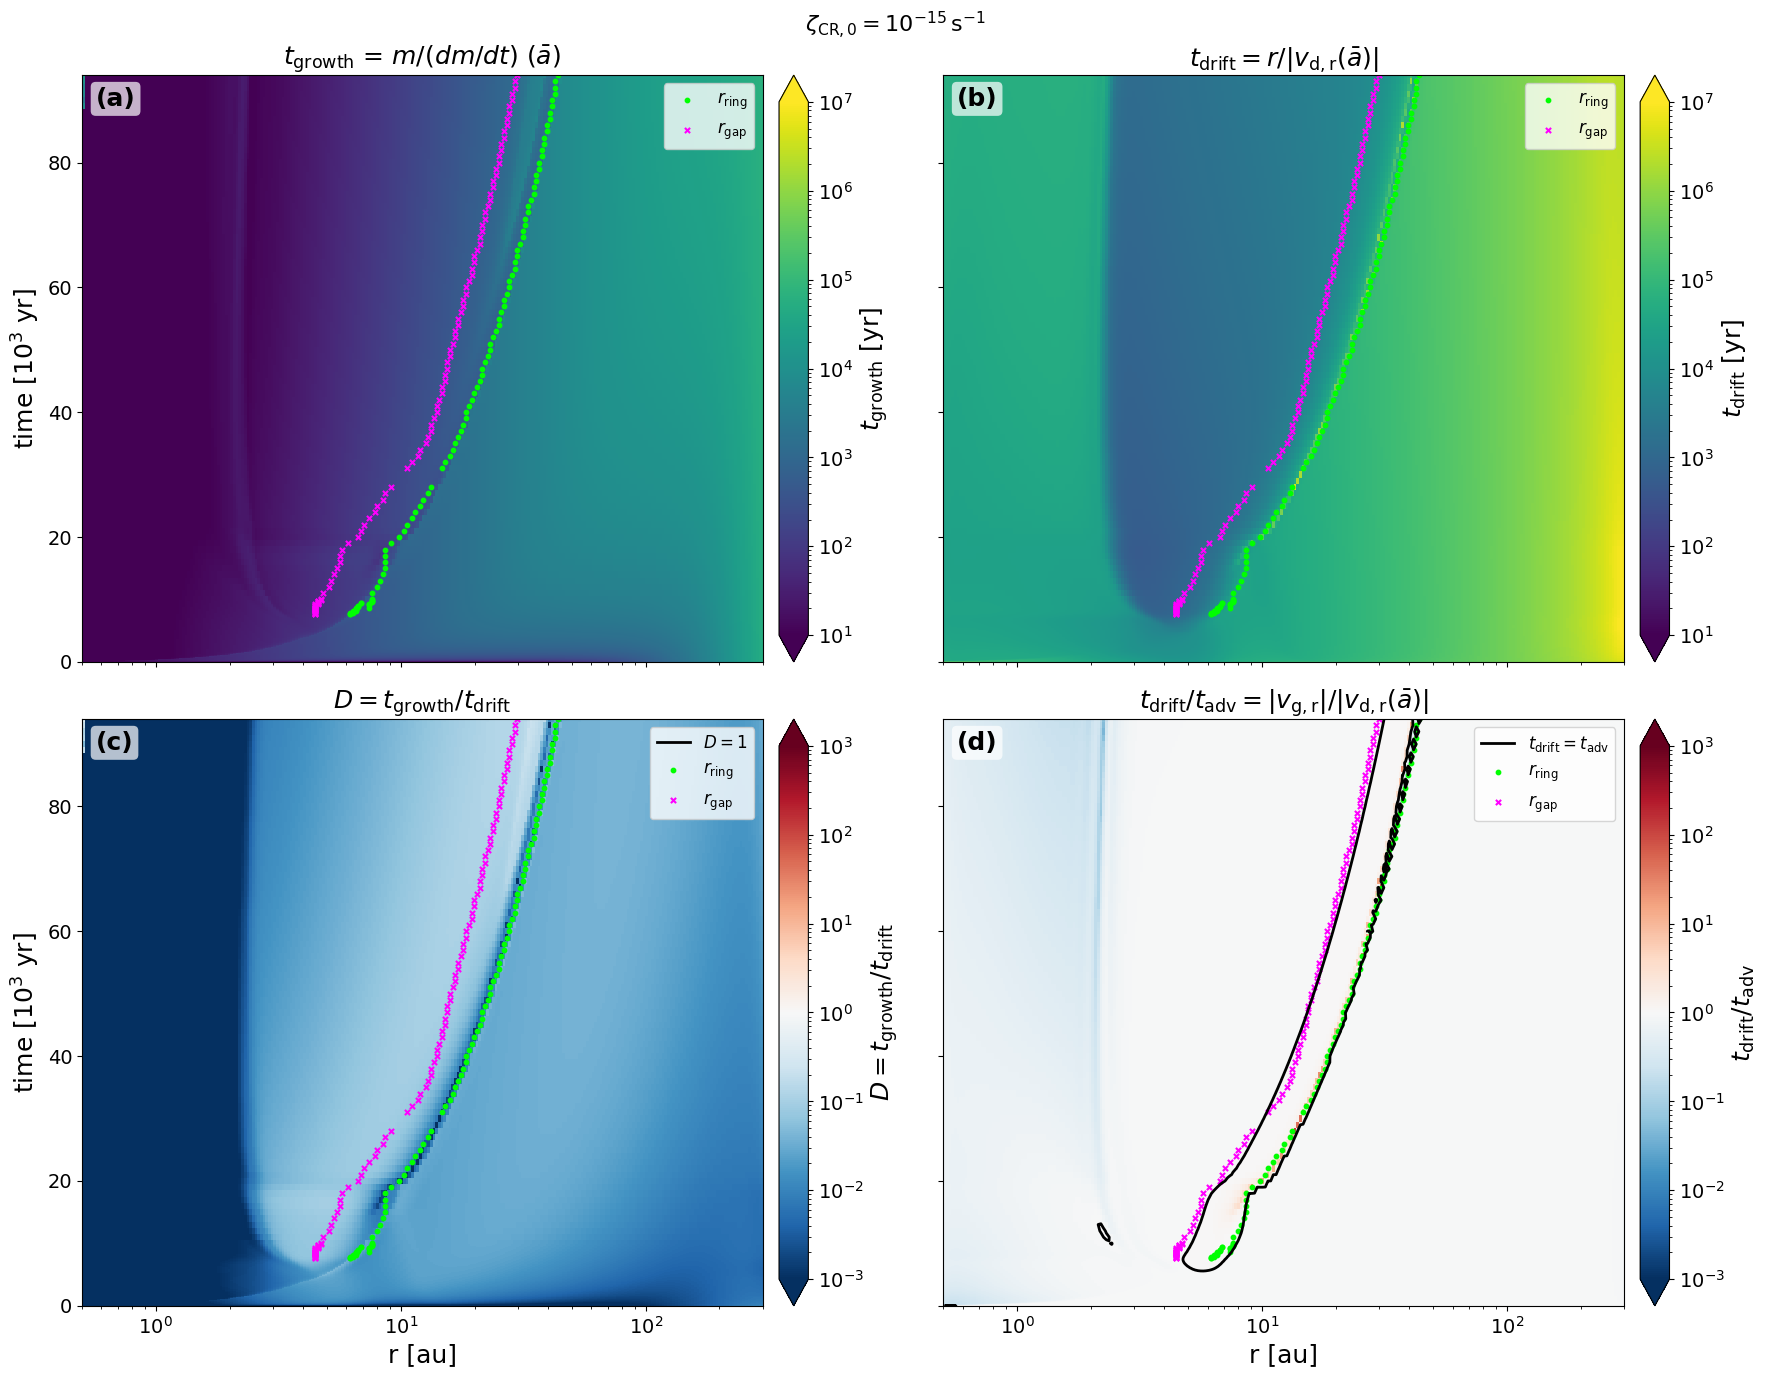

In [19]:
# [旧 cell 53]
# ======================================================
# 平均ダストサイズでの成長タイムスケール t_growth, ドリフトタイムスケール t_drift, 比 D = t_growth/t_drift,
# t_drift/t_adv の (r,t) 時空図 (2x2 ミニマップ) , 灰色は値なし (ダストなし / v_g,r = 0)
# 平均サイズ : a_mean = sum_j a_j Sigma_d,j / sum_j Sigma_d,j (面密度重み, 成長中の活性ダストのみ)
# St, H_d はコードと同じ式 (CalcStokesNumberAndDustScaleHeight)
#   St = pi/2 rho_int a/Sigma_g (a < 2.25 mfp) , 2 pi/9 rho_int a^2/(mfp Sigma_g) (a >= 2.25 mfp)
#   H_d = H_g min(1, sqrt(alpha_MRI / (min(St,0.5)(1+St^2))))
# t_growth : シングルサイズ近似 (Sato et al. 2016)
#   dm/dt = 2 sqrt(pi) a^2 Delta v Sigma_d,tot / H_d  ->  t_growth = m/(dm/dt) = (2 sqrt(pi)/3) rho_int a H_d / (Delta v Sigma_d,tot)
#   Delta v は St と 0.5 St の粒子間の相対速度 (ブラウン運動, 乱流 Ormel & Cuzzi 2007, 動径/方位角/鉛直ドリフト差;
#   コードの CalcDustRelativeVelocity と同じ式). growth_in_radius = True なら (d ln a/dt)^-1 = 3 m/(dm/dt)
# t_drift  : r / |v_d,r(a_mean)| , v_d,r はコードの CalcDustVelocity_TM2018 と同じ式
#   v_d,r = [(1 + A St^2) v_g,r + 2 St dv_g,phi - St^2 v_wind] / [1 + (1 + A) St^2]
#   dv_g,phi = v_g,phi - v_K , v_K = sqrt(G M_in/r) , A = 2 pi r^2 Sigma_g / M_in
#   M_in は Sigma_g から再構成 (M_in[0] = M_star + pi Sigma_g r_bod[1]^2 , 以降 + pi Sigma_g (r_bod[i+1]^2 - r_bod[i]^2))
# t_adv    : r / |v_g,r| (ガスの動径移流時間, v_g,r は file_gas 列4) -> t_drift/t_adv = |v_g,r| / |v_d,r(a_mean)|
# r_ring, r_gap は強度プロファイルのセル (t_ring, r_ring_t, t_gap, r_gap_t) の結果を重ねる
# file 列: out (3行目: a_j, 5行目以降: 0:r_cen 1~:Sigma_d,j)   out_gas 0:r_cen 1:sigmag 4:vg_r 5:vg_phi 6:vg_wind 12:T
#          out_B 1:alpha_MRI
# ======================================================

AU = 1.495979e+13
yr = 3.155760e+07
G = 6.67408e-08
kB = 1.38064852e-16
mg = 2.34 * 1.672621898e-24   # GAS_MOLECULAR_MASS
Msolar = 1.989000e+33
sigma_h2 = 2.0e-15

outdir = BASE_DIR
resultdir = MODEL
M_star = 1.0 * Msolar
rho_int = 1.4                 # ダストの内部密度 [g cm^-3] (input の rhodi)
growth_in_radius = False      # True: t_growth = (d ln a/dt)^-1 = 3 m/(dm/dt)
t_start = 0
t_range = (1.0e1, 1.0e7)      # t_growth, t_drift のカラーバー範囲 [yr]
D_range = 1.0e3               # D, t_drift/t_adv のカラーバー範囲 [1/D_range, D_range]
plot_ring_gap = True          # True: r_ring, r_gap を重ねる

path_gas = outdir + resultdir
path_mag = outdir + resultdir + "_B"
years = list_years(path_gas, t_start, path_mag=path_mag)

def stokes(a, sigmag, mfp):
    return np.where(a < 2.25 * mfp, 0.5 * np.pi * rho_int * a / sigmag,
                    2.0 * np.pi * rho_int * a**2 / (9.0 * mfp * sigmag))

def calc_timescales(year):
    f = path_gas + "/out{}".format(year)
    a_bin = np.array([float(x) for x in linecache.getline(f, 3).split()])
    linecache.clearcache()
    sigd_j = np.loadtxt(f, skiprows=5)[:, 1:]
    sigd_j = np.where(sigd_j > 0.0, sigd_j, 0.0)
    gas = np.loadtxt(path_gas + "/out{}_gas".format(year), usecols=(0, 1, 4, 5, 6, 12))
    r, sigmag, vgr, vgphi, vgw, T = gas.T
    alpha = np.loadtxt(path_mag + "/out{}_B".format(year), usecols=(1,))

    # M_in, v_K, A (log 格子: r_cen = sqrt(r_bod[i] r_bod[i+1]))
    q = r[1] / r[0]
    r_bod = np.append(r / np.sqrt(q), r[-1] * np.sqrt(q))
    dM = np.pi * sigmag * (r_bod[1:]**2 - r_bod[:-1]**2)
    dM[0] = np.pi * sigmag[0] * r_bod[1]**2
    M_in = M_star + np.cumsum(dM)
    Omega = np.sqrt(G * M_in / r**3)
    A = 2.0 * np.pi * r**2 * sigmag / M_in
    dvphi = vgphi - r * Omega
    cs = np.sqrt(kB * T / mg)
    Hg = cs / Omega
    mfp = 1.0 / (sigmag / (np.sqrt(2.0 * np.pi) * Hg) / mg * sigma_h2)

    vdr = lambda St: ((1.0 + A * St**2) * vgr + 2.0 * St * dvphi - St**2 * vgw) / (1.0 + (1.0 + A) * St**2)
    vdphi = lambda St: 0.5 * (-St * vgr + 2.0 * dvphi - St * vgw) / (1.0 + (1.0 + A) * St**2)
    Hd = lambda St: Hg * np.minimum(1.0, np.sqrt(alpha / (np.minimum(St, 0.5) * (1.0 + St**2))))

    # 平均サイズと, St が半分の相手粒子 (Epstein: a/2, Stokes: a/sqrt(2))
    sigd = sigd_j.sum(axis=1)
    ok = sigd > 0.0
    a1 = np.where(ok, (sigd_j @ a_bin) / np.where(ok, sigd, 1.0), a_bin[0])
    a2 = np.where(a1 / 2.0 < 2.25 * mfp, a1 / 2.0, a1 / np.sqrt(2.0))
    St1, St2 = stokes(a1, sigmag, mfp), stokes(a2, sigmag, mfp)
    m1, m2 = 4.0 / 3.0 * np.pi * rho_int * a1**3, 4.0 / 3.0 * np.pi * rho_int * a2**3

    # 相対速度 Delta v (CalcDustRelativeVelocity と同じ)
    vbr2 = 8.0 * kB / np.pi * T * (m1 + m2) / (m1 * m2)
    Stmin = 1.0 / np.sqrt(0.5 * alpha * sigmag * sigma_h2 / mg)   # 1/sqrt(Re)
    sTp = np.maximum(Stmin, np.minimum(1.6 * St1, 1.0))
    vI = (St1 - St2) / (St1 + St2) * (St1**2 / (sTp + St1) - St1**2 / (1.0 + St1)
                                      - St2**2 / (sTp + St2) + St2**2 / (1.0 + St2))
    vII = (sTp - Stmin) * (((sTp + Stmin) * St1 + sTp * Stmin) / ((St1 + sTp) * (St1 + Stmin))
                           + ((sTp + Stmin) * St2 + sTp * Stmin) / ((St2 + sTp) * (St2 + Stmin)))
    vt2 = alpha * cs**2 * (np.abs(vI) + np.abs(vII))
    dvr = vdr(St1) - vdr(St2)
    dvp = vdphi(St1) - vdphi(St2)
    dvz = (Hd(St1) * np.minimum(St1, 0.5) - Hd(St2) * np.minimum(St2, 0.5)) * Omega
    dv = np.sqrt(vbr2 + vt2 + dvr**2 + dvp**2 + dvz**2)

    t_grow = 2.0 * np.sqrt(np.pi) / 3.0 * rho_int * a1 * Hd(St1) / (dv * np.where(ok, sigd, 1.0))
    if growth_in_radius:
        t_grow *= 3.0
    t_drift = r / np.abs(vdr(St1))
    t_adv = np.where(vgr != 0.0, r / np.where(vgr != 0.0, np.abs(vgr), 1.0), np.nan)   # v_g,r = 0 (Sigma_g が下限) は nan
    return r, np.where(ok, t_grow / yr, np.nan), np.where(ok, t_drift / yr, np.nan), t_adv / yr

t_grow, t_drift, t_adv = [], [], []
for year in years:
    r, tg, td, ta = calc_timescales(year)
    t_grow.append(tg)
    t_drift.append(td)
    t_adv.append(ta)
t_grow, t_drift, t_adv = np.array(t_grow), np.array(t_drift), np.array(t_adv)
D = t_grow / t_drift
R_da = t_drift / t_adv

t = np.array(years) / 1.0e3
r_au = r / AU
tg_label = r"$(d\ln a/dt)^{-1}$" if growth_in_radius else r"$m/(dm/dt)$"
panels = [(t_grow, "viridis", LogNorm(vmin=t_range[0], vmax=t_range[1]),
           r"$t_{\rm growth}$ [yr]", r"$t_{\rm growth}$ = " + tg_label + r" ($\bar{a}$)"),
          (t_drift, "viridis", LogNorm(vmin=t_range[0], vmax=t_range[1]),
           r"$t_{\rm drift}$ [yr]", r"$t_{\rm drift} = r/|v_{\rm d,r}(\bar{a})|$"),
          (D, "RdBu_r", LogNorm(vmin=1.0 / D_range, vmax=D_range),
           r"$D = t_{\rm growth}/t_{\rm drift}$", r"$D = t_{\rm growth}/t_{\rm drift}$"),
          (R_da, "RdBu_r", LogNorm(vmin=1.0 / D_range, vmax=D_range),
           r"$t_{\rm drift}/t_{\rm adv}$", r"$t_{\rm drift}/t_{\rm adv} = |v_{\rm g,r}|/|v_{\rm d,r}(\bar{a})|$")]

fig, axes = plt.subplots(2, 2, figsize=(18, 14), sharex=True, sharey=True)
for n, (ax, (data, cmap, norm, cb_label, title)) in enumerate(zip(axes.flat, panels)):
    ax.set_facecolor("lightgray")
    pc = ax.pcolormesh(r_au, t, data, cmap=cmap, norm=norm, shading="nearest", rasterized=True)
    cb = fig.colorbar(pc, ax=ax, pad=0.02, extend="both")
    cb.set_label(cb_label, fontsize=18)
    cb.ax.tick_params(labelsize=14)
    handles = []
    if n >= 2:
        ax.contour(r_au, t, np.log10(data), levels=[0.0], colors="black", linewidths=2.0)
        handles.append(Line2D([], [], color="black", lw=2.0, label=r"$D = 1$" if n == 2 else r"$t_{\rm drift} = t_{\rm adv}$"))
    if plot_ring_gap:
        t_ring_k, t_gap_k = np.array(t_ring) / 1.0e3, np.array(t_gap) / 1.0e3
        m_ring, m_gap = t_ring_k >= t[0], t_gap_k >= t[0]
        ax.scatter(np.array(r_ring_t)[m_ring] / AU, t_ring_k[m_ring], s=10, color="lime", label=r"$r_{\rm ring}$")
        ax.scatter(np.array(r_gap_t)[m_gap] / AU, t_gap_k[m_gap], s=14, marker="x", color="magenta", label=r"$r_{\rm gap}$")
        handles += ax.get_legend_handles_labels()[0]
    ax.set_xscale("log")
    ax.set_xlim((r_min, r_max))
    ax.set_ylim((t_min, t_max))
    ax.set_title(title, fontsize=18)
    ax.tick_params(labelsize=14)
    if handles:
        ax.legend(handles=handles, fontsize=12, loc="upper right")
for ax in axes[1, :]:
    ax.set_xlabel("r [au]", fontsize=18)
for ax in axes[:, 0]:
    ax.set_ylabel(r"time [$10^3$ yr]", fontsize=18)
fig.suptitle(model_names[resultdir], fontsize=16)
plt.tight_layout()
plt.show()

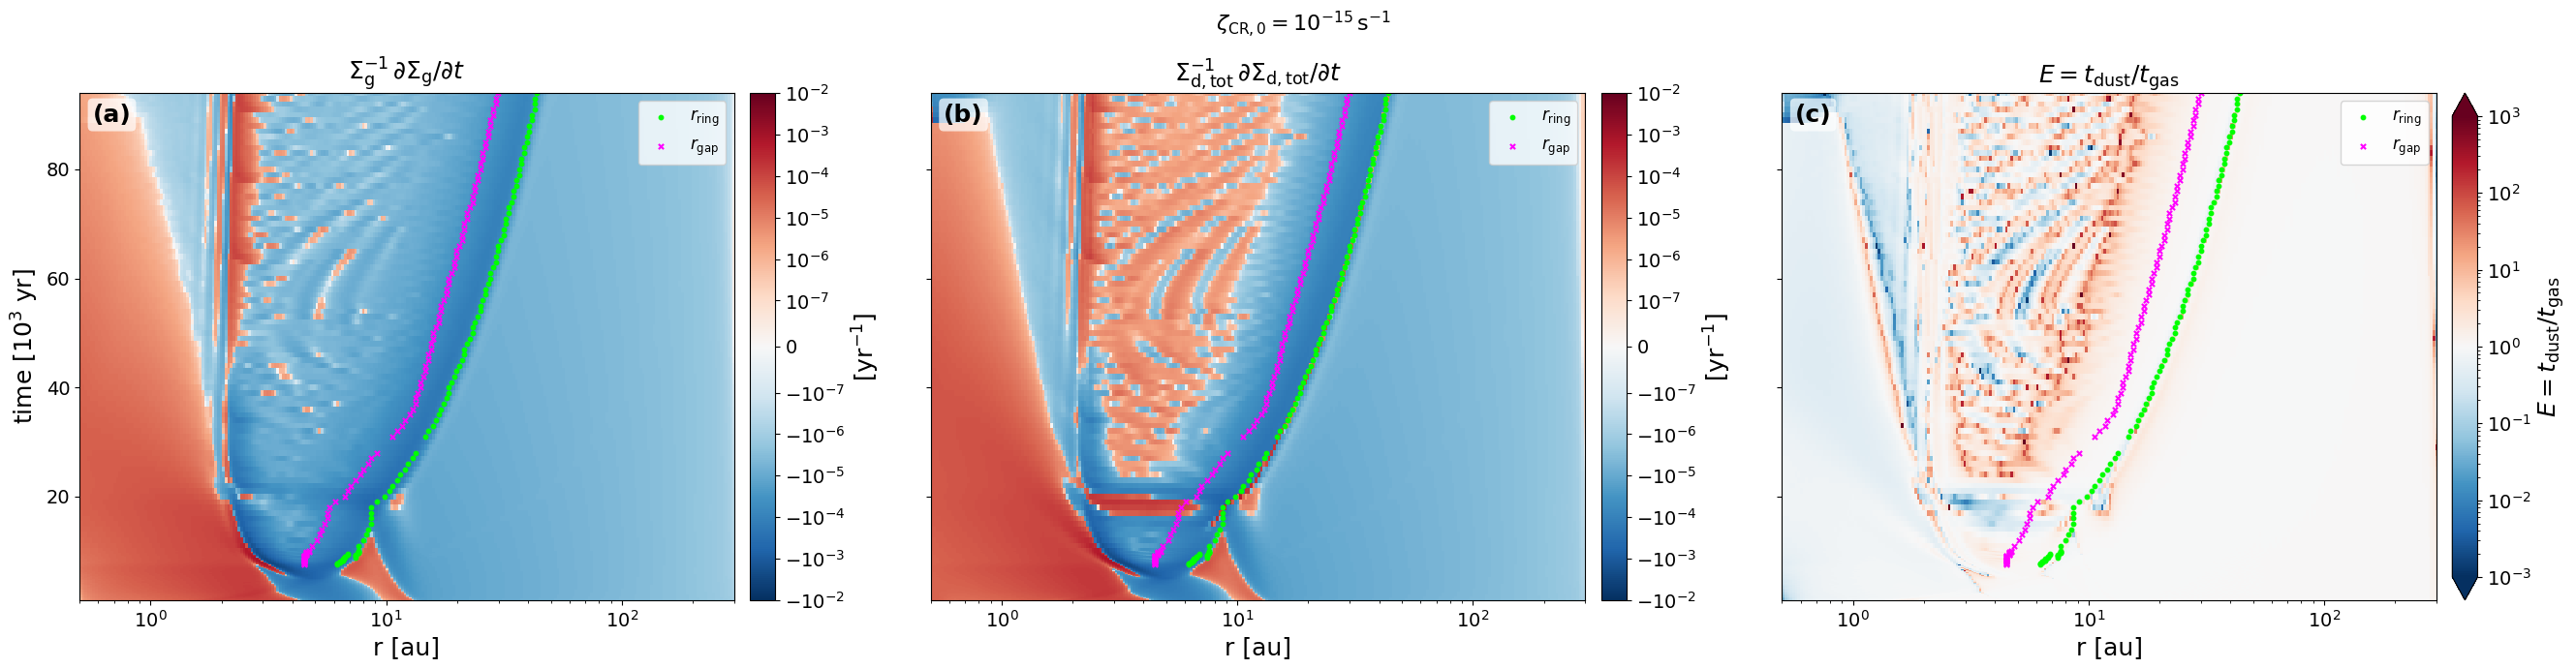

In [20]:
# [旧 cell 54]
# ======================================================
# (1/Sigma_g) dSigma_g/dt , (1/Sigma_d,tot) dSigma_d,tot/dt , E = t_dust/t_gas の (r,t) 時空図 (1x3 ミニマップ) + r_ring, r_gap
# dSigma_g/dt     : cell 46 の calc_dSdt (フラックス形式)
# dSigma_d,tot/dt : cell 53 の calc_dSddt (フラックス形式, 蒸気を含む)  -> cell 46, 53 を先に実行すること
# t_gas = 1/|(1/Sigma_g) dSigma_g/dt| , t_dust = 1/|(1/Sigma_d,tot) dSigma_d,tot/dt|
# E = t_dust/t_gas : E < 1 ならダストの方が速く変化, E > 1 ならガスの方が速く変化
# file_gas 列: 0:r_cen 1:sigmag 2:sigmad_tot 4:vg_r 11:dsigmagdt_w
# 単位は yr^-1, 相対変化率は SymLogNorm (赤: 増加, 青: 減少), E は LogNorm (E = 1 が白), 灰色は値なし
# ======================================================

AU = 1.495979e+13
yr = 3.155760e+07

outdir = BASE_DIR
resultdir = MODEL
t_start = 1000
rel_max, rel_lin = 1.0e-2, 1.0e-7   # 相対変化率のカラーバー範囲 [yr^-1]
E_range = 1.0e3                     # E のカラーバー範囲 [1/E_range, E_range]
plot_ring_gap = True                # True: r_ring, r_gap を重ねる
plot_E1_contour = False             # True: E = 1 の等高線 (E ~ 1 の領域が広いと線が込み入る)

path_gas = outdir + resultdir
path_mag = outdir + resultdir + "_B"
years = list_years(path_gas, t_start, path_mag=path_mag)

rel_g, rel_d = [], []
for year in years:
    gas = np.loadtxt(path_gas + "/out{}_gas".format(year), usecols=(0, 1, 2, 4, 11))
    r, sig, sigd, vgr, dsdt_w = gas.T
    rel_g.append(calc_dSdt(r, sig, vgr, dsdt_w) / sig * yr)
    rel_d.append(np.where(sigd > 0.0, calc_dSddt(year) / np.where(sigd > 0.0, sigd, 1.0), np.nan) * yr)
rel_g, rel_d = np.array(rel_g), np.array(rel_d)
with np.errstate(divide="ignore", invalid="ignore"):
    E = np.abs(rel_g) / np.abs(rel_d)   # = t_dust/t_gas
E = np.where(np.isfinite(E) & (E > 0.0), E, np.nan)

t = np.array(years) / 1.0e3
r_au = r / AU
panels = [(rel_g, "RdBu_r", SymLogNorm(linthresh=rel_lin, vmin=-rel_max, vmax=rel_max, base=10),
           r"[yr$^{-1}$]", r"$\Sigma_{\rm g}^{-1}\,\partial \Sigma_{\rm g}/\partial t$"),
          (rel_d, "RdBu_r", SymLogNorm(linthresh=rel_lin, vmin=-rel_max, vmax=rel_max, base=10),
           r"[yr$^{-1}$]", r"$\Sigma_{\rm d,tot}^{-1}\,\partial \Sigma_{\rm d,tot}/\partial t$"),
          (E, "RdBu_r", LogNorm(vmin=1.0 / E_range, vmax=E_range),
           r"$E = t_{\rm dust}/t_{\rm gas}$", r"$E = t_{\rm dust}/t_{\rm gas}$")]

fig, axes = plt.subplots(1, 3, figsize=(27, 7), sharey=True)
for n, (ax, (data, cmap, norm, cb_label, title)) in enumerate(zip(axes, panels)):
    ax.set_facecolor("lightgray")
    pc = ax.pcolormesh(r_au, t, data, cmap=cmap, norm=norm, shading="nearest", rasterized=True)
    cb = fig.colorbar(pc, ax=ax, pad=0.02, extend="both" if n == 2 else "neither")
    cb.set_label(cb_label, fontsize=18)
    cb.ax.tick_params(labelsize=14)
    handles = []
    if n == 2 and plot_E1_contour:
        ax.contour(r_au, t, np.log10(E), levels=[0.0], colors="black", linewidths=2.0)
        handles.append(Line2D([], [], color="black", lw=2.0, label=r"$E = 1$"))
    if plot_ring_gap:
        t_ring_k, t_gap_k = np.array(t_ring) / 1.0e3, np.array(t_gap) / 1.0e3
        m_ring, m_gap = t_ring_k >= t[0], t_gap_k >= t[0]
        ax.scatter(np.array(r_ring_t)[m_ring] / AU, t_ring_k[m_ring], s=10, color="lime", label=r"$r_{\rm ring}$")
        ax.scatter(np.array(r_gap_t)[m_gap] / AU, t_gap_k[m_gap], s=14, marker="x", color="magenta", label=r"$r_{\rm gap}$")
        handles += ax.get_legend_handles_labels()[0]
    ax.set_xscale("log")
    ax.set_xlim((r_min, r_max))
    ax.set_ylim((t[0], t[-1]))
    ax.set_xlabel("r [au]", fontsize=18)
    ax.set_title(title, fontsize=18)
    ax.tick_params(labelsize=14)
    if handles:
        ax.legend(handles=handles, fontsize=12, loc="upper right")
axes[0].set_ylabel(r"time [$10^3$ yr]", fontsize=18)
fig.suptitle(model_names[resultdir], fontsize=16)
plt.tight_layout()
plt.show()